# Process the SNEMI3D instances: instance -> skeleton / wiremesh / gaussian

`docs/TERMINOLOGY.md` names six representations of the same tissue. The first two (`rawvalue`, `voxvalue`) are the EM
intensities; the last four describe a **neuron**:

| name | what it is | container (`ncntm/viz/types.py`) | converter (`ncntm/viz/convert.py`) |
|---|---|---|---|
| `instance` | voxel label = neuron id | `uint` array (z, y, x) | - |
| `skeleton` | centre-line tree with a radius per node | `Skeleton` | `instance_to_skeleton` (kimimaro / TEASAR) |
| `wiremesh` | closed triangle surface | `Mesh` | `instance_to_mesh` (marching cubes, zmesh) |
| `gaussian` | mixture of 3D Gaussians (mean, covariance, weight) | `Gaussians` | `instance_to_gaussians` (k-means in nm) |

This notebook runs those conversions on **every instance of `AC4_labels.h5`** (100 x 1024 x 1024 voxels of
6 x 6 x 30 nm, 400 neurons), adds one conversion that the library does not have (**skeleton -> gaussian**), and measures
what each representation keeps, what it loses and what it costs.

Conventions are the ones of `ncntm.viz.grid`: arrays are `(z, y, x)`, geometry is `(x, y, z)` in true nanometres, voxel
`[k, j, i]` is the box `[i dx, (i+1) dx] x ...`. Every instance is converted on its own tight crop (plus 1 voxel of
margin, never beyond the array), so all geometry below is in the **local frame of that crop**. Lengths and sizes do not
depend on that frame.

Section map: 1 data and inventory - 2 convert everything - 3 look at four instances - 4 skeleton insight - 5 wiremesh insight - 6 gaussian insight and the skeleton -> gaussian path - 7 what ignoring anisotropy costs - 8 cost versus fidelity - **9 progression `voxel -> frame -> graph` (`wiremesh` to `gaussian`)** - **10 special session: optimizing Gaussian blob count** - 11 findings.

In [1]:
import os, re, time, warnings
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from scipy import stats
from mpl_toolkits.mplot3d.art3d import Line3DCollection, Poly3DCollection

# ---- parameters: change and re-run ------------------------------------------------------------
LABELS = "AC4_labels.h5"        # data/SNEMI3D/<file>; the voxel size is parsed from docs/DATASETS.md
IMAGE = "AC4_em_inputs.h5"      # only used to show a slice next to the labels
MAX_INSTANCES = None            # None = all 400; an int = the largest N (quick test)
K_LIST = (1, 4, 16, 64)         # mixture sizes tried for instance -> gaussian
SKEL_K_LIST = (4, 16, 64)       # target sizes for skeleton -> gaussian (the result has about that many)
SHOW_RANKS = (0, 25, 100, 250)  # instances drawn in section 3, by size rank (0 = largest)
BALL_SCALES = (1.25, 1.5, 2.0)  # skeleton balls redrawn with radius x this, to see how far the radius is from the true half width
INFLATE = 1.25                  # radius factor for the second skeleton -> gaussian variant (see section 4: best ball IoU)
TAU = 5.0                       # Mahalanobis^2 of a Gaussian's "solid" ellipsoid: a uniform ellipsoid with semi-axes
                                # a, b, c has covariance diag(a^2, b^2, c^2) / 5 (see single_gaussian in convert.py)
WORKERS = 32                    # processes for section 2 (1 = run in this process)
# -----------------------------------------------------------------------------------------------


def find_repo(start=None):
    start = Path(start or Path.cwd()).resolve()
    for p in [start, *start.parents]:
        if (p / "docs" / "DATASETS.md").is_file():
            return p
    raise FileNotFoundError("Open this notebook from inside the ncntm repo (docs/DATASETS.md not found).")


REPO = find_repo()
import sys
sys.path.insert(0, str(REPO))
from ncntm.viz.grid import VoxelGrid
from ncntm.viz import convert as C
from ncntm.viz.types import Gaussians, Skeleton

DATA = Path(os.environ.get("NCNTM_DATA_DIR", REPO / "data")) / "SNEMI3D"
DOC_TEXT = (REPO / "docs" / "DATASETS.md").read_text()

# voxel size: the doc row of the matching crop ("Voxel size (x x y x z nm)" = "6 x 6 x 30")
crop_name = LABELS.split("_labels")[0] + "_em"
row = next(l for l in DOC_TEXT.splitlines() if l.startswith("|") and f"| {crop_name} |" in l)
vx, vy, vz = (float(v) for v in re.findall(r"[\d.]+", row.split("|")[8]))
VOX_ZYX = (vz, vy, vx)
print("repo :", REPO)
print("data :", DATA / LABELS)
print("voxel:", f"{vx:g} x {vy:g} x {vz:g} nm (x, y, z) from the doc row of {crop_name}")

repo : /home/nvidia/ncntm
data : /home/nvidia/ncntm/data/SNEMI3D/AC4_labels.h5
voxel: 6 x 6 x 30 nm (x, y, z) from the doc row of AC4_em


## 1. Data and inventory

`AC4_labels.h5` is stored with z, y and x all reversed with respect to BossDB (see `docs/DATASETS.md`). That does not
matter for anything below: every number is a distance, an area, a volume or a count, and those do not change when the
axes are reversed.

1024 x 1024 x 100 voxels (x, y, z) of 6 x 6 x 30 nm = 6.14 x 6.14 x 3.00 um, anisotropy 5:1
labels: (100, 1024, 1024) uint16 ids 0 .. 400
400 instances; background 10.2%; voxels per instance: max 4,919,028, median 89,350, min 2,180


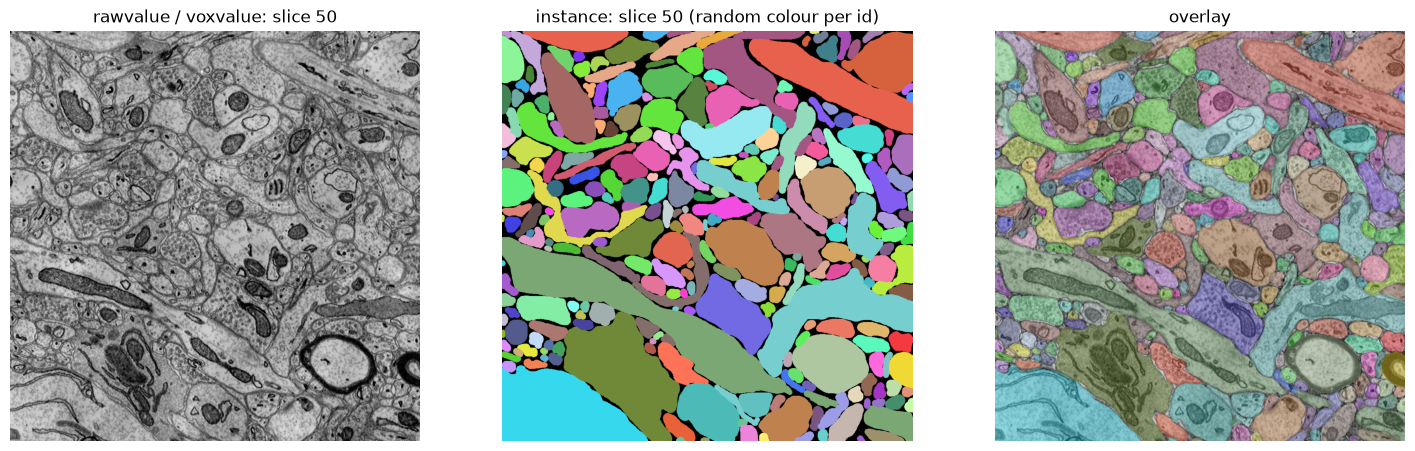

In [2]:
LAB = h5py.File(DATA / LABELS, "r")["main"][...]
IMG = h5py.File(DATA / IMAGE, "r")["main"]
GRID = VoxelGrid(LAB.shape, VOX_ZYX)
print(GRID.describe())
print("labels:", LAB.shape, LAB.dtype, "ids 0 ..", int(LAB.max()))

COUNTS = np.bincount(LAB.ravel())
SLICES = ndi.find_objects(LAB.astype(np.int32))            # tight bounding box of id i is SLICES[i - 1]
IDS = np.array([i for i in range(1, len(COUNTS)) if COUNTS[i] > 0 and SLICES[i - 1] is not None])
IDS = IDS[np.argsort(-COUNTS[IDS])]                        # largest first
if MAX_INSTANCES:
    IDS = IDS[:MAX_INSTANCES]
SHOW_RANKS = tuple(sorted({min(r, len(IDS) - 1) for r in SHOW_RANKS}))   # clamp ranks when MAX_INSTANCES is small
print(f"{len(IDS)} instances; background {COUNTS[0] / LAB.size:.1%}; voxels per instance: "
      f"max {COUNTS[IDS].max():,}, median {int(np.median(COUNTS[IDS])):,}, min {COUNTS[IDS].min():,}")


def crop_instance(i, margin=1):
    # Bool mask of instance i on its bounding box (+ margin voxels, clipped to the array) and the VoxelGrid of that crop.
    sl = tuple(slice(max(s.start - margin, 0), min(s.stop + margin, n)) for s, n in zip(SLICES[i - 1], LAB.shape))
    sub = LAB[sl] == i
    return sub, VoxelGrid(sub.shape, VOX_ZYX), sl


rng = np.random.default_rng(0)
z0 = 50
lab_rgb = np.zeros(LAB.shape[1:] + (3,))
cols = rng.random((LAB.max() + 1, 3)) * 0.8 + 0.2
cols[0] = 0
fig, axs = plt.subplots(1, 3, figsize=(18, 6))
axs[0].imshow(IMG[z0], cmap="gray"); axs[0].set_title(f"rawvalue / voxvalue: slice {z0}")
axs[1].imshow(cols[LAB[z0]]); axs[1].set_title(f"instance: slice {z0} (random colour per id)")
axs[2].imshow(IMG[z0], cmap="gray"); axs[2].imshow(cols[LAB[z0]], alpha=np.where(LAB[z0] > 0, 0.45, 0.0))
axs[2].set_title("overlay")
for a in axs: a.axis("off")
plt.show()

inventory in 31 s
instance volume: median 0.096 um^3, max 5.3 um^3, min 0.0024 um^3
instances in one piece: 99.2%;  pieces per instance: median 1, max 2
instances touching the array border: 100.0%  (faces touched: median 2, max 5)
the largest 10 instances hold 31.8% of all labelled voxels


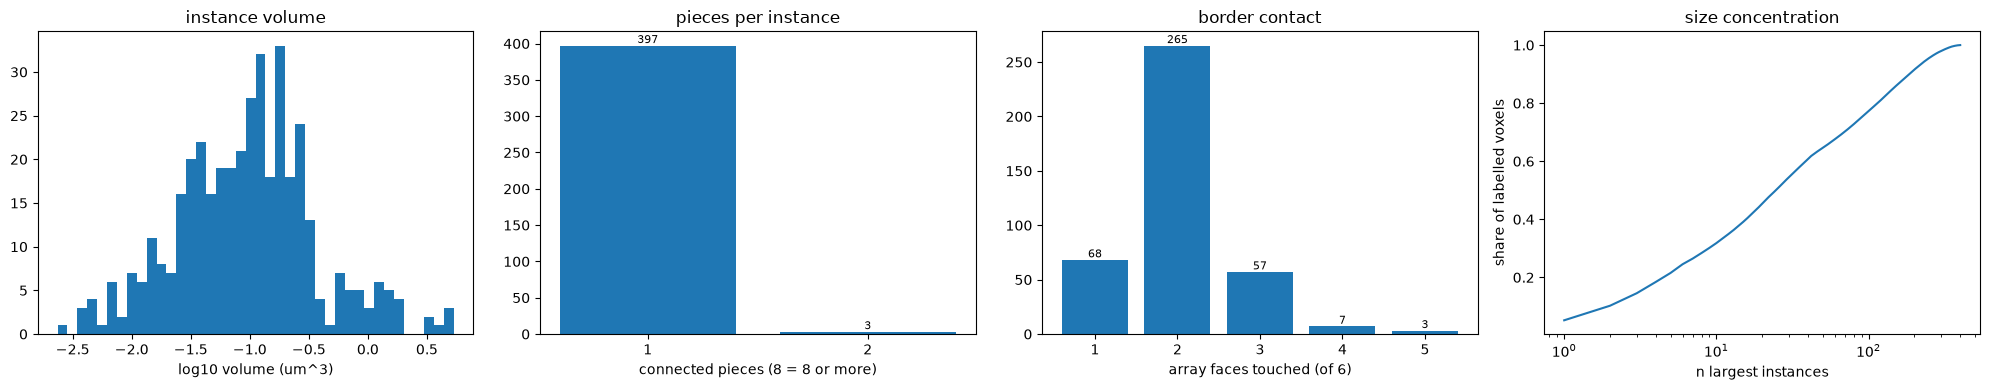

In [3]:
# Inventory per instance: size, connected pieces, contact with the six faces of the array.
FACES = ("z0", "z1", "y0", "y1", "x0", "x1")


def inventory(i):
    tight = SLICES[i - 1]
    sub = LAB[tight] == i
    _, n_comp = ndi.label(sub)                                       # 6-connected pieces
    sizes = np.bincount(ndi.label(sub)[0].ravel())[1:]
    touch = []
    for a in range(3):
        touch += [tight[a].start == 0, tight[a].stop == LAB.shape[a]]
    return dict(id=int(i), n_vox=int(COUNTS[i]), n_comp=int(n_comp), largest_piece=float(sizes.max() / sizes.sum()),
                n_faces_touched=int(sum(touch)), **{f"touch_{f}": t for f, t in zip(FACES, touch)},
                bbox_zyx=tuple(s.stop - s.start for s in tight))


t0 = time.time()
INV = pd.DataFrame([inventory(i) for i in IDS]).set_index("id")
print(f"inventory in {time.time() - t0:.0f} s")
vol_um3 = INV.n_vox * float(np.prod(GRID.voxel_size_xyz_nm)) / 1e9
print(f"instance volume: median {vol_um3.median():.3f} um^3, max {vol_um3.max():.1f} um^3, min {vol_um3.min():.4f} um^3")
print(f"instances in one piece: {(INV.n_comp == 1).mean():.1%};  pieces per instance: median {INV.n_comp.median():.0f}, max {INV.n_comp.max()}")
print(f"instances touching the array border: {(INV.n_faces_touched > 0).mean():.1%}  "
      f"(faces touched: median {INV.n_faces_touched.median():.0f}, max {INV.n_faces_touched.max()})")
print(f"the largest 10 instances hold {COUNTS[IDS[:10]].sum() / COUNTS[IDS].sum():.1%} of all labelled voxels")

fig, axs = plt.subplots(1, 4, figsize=(20, 4))
axs[0].hist(np.log10(vol_um3), bins=40); axs[0].set_xlabel("log10 volume (um^3)"); axs[0].set_title("instance volume")
for a_, col_, lab_, ttl_ in ((axs[1], INV.n_comp.clip(upper=8), "connected pieces (8 = 8 or more)", "pieces per instance"),
                             (axs[2], INV.n_faces_touched, "array faces touched (of 6)", "border contact")):
    vals_, cnt_ = np.unique(col_, return_counts=True)
    a_.bar(vals_, cnt_); a_.set_xticks(vals_); a_.set_xlabel(lab_); a_.set_title(ttl_)
    for x_, y_ in zip(vals_, cnt_):
        a_.text(x_, y_, str(y_), ha="center", va="bottom", fontsize=8)
cum = np.cumsum(COUNTS[IDS]) / COUNTS[IDS].sum()
axs[3].plot(np.arange(1, len(IDS) + 1), cum); axs[3].set_xscale("log")
axs[3].set_xlabel("n largest instances"); axs[3].set_ylabel("share of labelled voxels"); axs[3].set_title("size concentration")
fig.tight_layout(); plt.show()

## 2. Convert every instance

Per instance, on its crop:

* **skeleton**: `instance_to_skeleton(dust_nm3=0)` (every piece is kept); raw cable length and the length after
  `smooth_skeleton` with a window of 4 x the largest voxel edge (120 nm).
* **wiremesh**: `instance_to_mesh` unsimplified, and with `simplify_factor=10`.
* **gaussian**: `instance_to_gaussians(k)` for `K_LIST`, and the new **skeleton -> gaussian** below for `SKEL_K_LIST`.

Fidelity is measured by drawing the representation back into the voxel grid and comparing with the instance:
`rasterise_ellipsoids` marks every voxel whose centre lies inside one of the ellipsoids `(x-mu)^T S^-1 (x-mu) <= TAU`.
`TAU = 5` is the ellipsoid of the *uniform solid* with that covariance, so a mixture fitted to a solid is compared at its
natural size. The same function draws a skeleton as a union of balls (radius = node radius, `S = r^2/5 I`). We report
`recall` (share of instance voxels covered), `precision` (share of covered voxels that are the instance) and `IoU`.
A wiremesh needs no drawing: marching cubes on a mask is lossless up to corner cutting, which is measured as the
ratio of mesh volume to voxel volume.

In [4]:
def rasterise_ellipsoids(means_xyz, covs, grid, tau=TAU, slab=2_000_000):
    # Union of the ellipsoids (x-mu)^T S^-1 (x-mu) <= tau as a bool (z, y, x) array on `grid` (nm, local frame).
    vox = grid.voxel_size_xyz_nm
    shp = grid.shape_xyz
    out = np.zeros(grid.shape_zyx, bool)
    prec = np.linalg.inv(covs)
    half = np.sqrt(tau * np.diagonal(covs, axis1=1, axis2=2))             # half extent of each ellipsoid's bounding box
    lo_all = np.maximum(np.ceil((means_xyz - half) / vox - 0.5), 0).astype(int)
    hi_all = np.minimum(np.floor((means_xyz + half) / vox - 0.5), shp - 1).astype(int)
    for mu, P, lo, hi in zip(means_xyz, prec, lo_all, hi_all):
        if (hi < lo).any():
            continue
        xs = (np.arange(lo[0], hi[0] + 1) + 0.5) * vox[0] - mu[0]
        ys = (np.arange(lo[1], hi[1] + 1) + 0.5) * vox[1] - mu[1]
        zs = (np.arange(lo[2], hi[2] + 1) + 0.5) * vox[2] - mu[2]
        dy, dx = ys[None, :, None], xs[None, None, :]
        step = max(1, slab // (len(ys) * len(xs)))                          # z-slabs bound the memory of big ellipsoids
        for a in range(0, len(zs), step):
            dz = zs[a:a + step, None, None]
            q = (P[0, 0] * dx * dx + P[1, 1] * dy * dy + P[2, 2] * dz * dz
                 + 2 * (P[0, 1] * dx * dy + P[0, 2] * dx * dz + P[1, 2] * dy * dz))
            out[lo[2] + a:lo[2] + a + dz.shape[0], lo[1]:hi[1] + 1, lo[0]:hi[0] + 1] |= q <= tau
    return out


def overlap(drawn, mask):
    inter = int(np.count_nonzero(drawn & mask))
    n_d, n_m = int(np.count_nonzero(drawn)), int(np.count_nonzero(mask))
    return dict(iou=inter / max(n_d + n_m - inter, 1), recall=inter / max(n_m, 1), precision=inter / max(n_d, 1))


def draw_gaussians(g, grid):
    return rasterise_ellipsoids(g.means_xyz_nm, g.covariances_nm2, grid)


def draw_skeleton(sk, grid, scale=1.0):
    r = np.asarray(sk.radii_nm) * scale
    covs = (r ** 2 / 5.0)[:, None, None] * np.eye(3)[None]
    return rasterise_ellipsoids(sk.vertices_xyz_nm, covs, grid)


def skeleton_to_gaussians(sk, k, instance_id=0, radius_scale=1.0):
    # skeleton -> gaussian: cut every chain between branch/end points into pieces of about cable/k nm and
    # moment-match each piece. A node is a ball of radius r (covariance r^2/5 I) carrying the volume pi r^2 * (cable
    # length it stands for); a piece has the weighted mean of its nodes and the weighted sum of
    # (ball covariance + spread of the node positions).  No voxel is looked at: only the skeleton.
    v = np.asarray(sk.vertices_xyz_nm, float)
    r = np.asarray(sk.radii_nm, float) * radius_scale
    e = np.asarray(sk.edges)
    n = len(v)
    elen = np.linalg.norm(v[e[:, 0]] - v[e[:, 1]], axis=1)
    node_len = np.zeros(n)
    np.add.at(node_len, e[:, 0], 0.5 * elen)
    np.add.at(node_len, e[:, 1], 0.5 * elen)
    node_len = np.maximum(node_len, 2 * r)                                    # an isolated node is a ball
    seg = max(sk.cable_length_nm() / max(int(k), 1), 1e-9)
    group = np.full(n, -1)
    nxt = 0
    for chain in sk.polylines():
        p = v[chain]
        s = np.r_[0.0, np.cumsum(np.linalg.norm(np.diff(p, axis=0), axis=1))]
        m = max(1, int(round(s[-1] / seg)))
        cid = np.minimum((s / max(s[-1], 1e-9) * m).astype(int), m - 1)
        for node, c in zip(chain, cid):
            if group[node] < 0:
                group[node] = nxt + c
        nxt += m
    lone = group < 0
    group[lone] = nxt + np.arange(lone.sum())
    _, group = np.unique(group, return_inverse=True)
    K = group.max() + 1
    w = np.pi * r ** 2 * node_len
    mean = np.stack([np.bincount(group, weights=w * v[:, a], minlength=K) for a in range(3)], 1)
    W = np.bincount(group, weights=w, minlength=K)
    mean /= W[:, None]
    d = v - mean[group]
    cov = np.zeros((K, 3, 3))
    for a in range(3):
        for b in range(a, 3):
            cov[:, a, b] = cov[:, b, a] = np.bincount(group, weights=w * d[:, a] * d[:, b], minlength=K) / W
    cov += (np.bincount(group, weights=w * r ** 2 / 5.0, minlength=K) / W)[:, None, None] * np.eye(3)
    return Gaussians(mean, cov, W / W.sum(), C.PALETTE_RGB[np.arange(K) % len(C.PALETTE_RGB)], instance_id=int(instance_id))


def nbytes(sk=None, mesh=None, g=None):
    # float32 / int32 storage of each representation
    if sk is not None:
        return 4 * (4 * len(sk.vertices_xyz_nm) + 2 * len(sk.edges))
    if mesh is not None:
        return 4 * (3 * len(mesh.vertices_xyz_nm) + 3 * len(mesh.faces))
    return 4 * len(g) * (3 + 6 + 1)                                           # mean, symmetric covariance, weight


def convert_one(i):
    sub, grid, _ = crop_instance(i)
    rec = dict(id=int(i), n_vox=int(sub.sum()), bbox_vox=int(sub.size), mask_bytes=sub.size / 8.0)
    vox_nm3 = float(np.prod(grid.voxel_size_xyz_nm))
    rec["volume_nm3"] = rec["n_vox"] * vox_nm3
    # ---- skeleton
    t = time.perf_counter()
    try:
        sk = C.instance_to_skeleton(sub, grid, dust_nm3=0.0, instance_id=i)
    except ValueError as err:
        sk, rec["skel_error"] = None, str(err)[:80]
    rec["t_skel"] = time.perf_counter() - t
    if sk is not None:
        sm = C.smooth_skeleton(sk, 4.0 * float(grid.voxel_size_xyz_nm.max()))
        rec.update(skel_nodes=len(sk.vertices_xyz_nm), skel_edges=len(sk.edges), cable_nm=sk.cable_length_nm(),
                   cable_smooth_nm=sm.cable_length_nm(), n_branch=sk.n_branch_points(), n_end=sk.n_end_points(),
                   mean_radius_nm=C.mean_radius_nm(sk), max_radius_nm=float(sk.radii_nm.max()),
                   n_skel_trees=len(sk.vertices_xyz_nm) - len(sk.edges),
                   skel_bytes=nbytes(sk=sk))
        rec.update({f"skel_ball_{k}": v for k, v in overlap(draw_skeleton(sk, grid), sub).items()})
        for sc in BALL_SCALES:                                                   # same balls with the radius inflated
            ov = overlap(draw_skeleton(sk, grid, sc), sub)
            rec[f"skel_ball{round(100 * sc)}_iou"] = ov["iou"]
            rec[f"skel_ball{round(100 * sc)}_precision"] = ov["precision"]
    # ---- wiremesh
    t = time.perf_counter()
    try:
        mesh = C.instance_to_mesh(sub, grid, instance_id=i)
        rec.update(mesh_faces=len(mesh.faces), mesh_verts=len(mesh.vertices_xyz_nm), mesh_edges=len(mesh.edges()),
                   mesh_area_nm2=mesh.area_nm2(), mesh_vol_nm3=mesh.volume_nm3(), mesh_bytes=nbytes(mesh=mesh))
        rec["t_mesh"] = time.perf_counter() - t
        if len(mesh.faces) > 200:
            ms = C.instance_to_mesh(sub, grid, simplify_factor=10, instance_id=i)
            rec.update(mesh10_faces=len(ms.faces), mesh10_vol_nm3=ms.volume_nm3(), mesh10_area_nm2=ms.area_nm2(),
                       mesh10_bytes=nbytes(mesh=ms))
    except Exception as err:
        rec["mesh_error"] = str(err)[:80]
    # ---- gaussian from voxels
    for k in K_LIST:
        t = time.perf_counter()
        g = C.instance_to_gaussians(sub, grid, k=k, instance_id=i)
        rec[f"t_gauss{k}"] = time.perf_counter() - t
        rec[f"gauss{k}_n"] = len(g)
        rec[f"gauss{k}_bytes"] = nbytes(g=g)
        rec[f"gauss{k}_elong_med"] = float(np.median(g.elongation()))
        rec.update({f"gauss{k}_{a}": b for a, b in overlap(draw_gaussians(g, grid), sub).items()})
    # ---- gaussian from the skeleton
    if sk is not None:
        for k in SKEL_K_LIST:
            g = skeleton_to_gaussians(sk, k, instance_id=i)
            rec[f"sg{k}_n"] = len(g)
            rec.update({f"sg{k}_{a}": b for a, b in overlap(draw_gaussians(g, grid), sub).items()})
            gx = skeleton_to_gaussians(sk, k, instance_id=i, radius_scale=INFLATE)   # radius inflated: the fix for the inscribed radius
            rec.update({f"sgx{k}_{a}": b for a, b in overlap(draw_gaussians(gx, grid), sub).items()})
            gv = C.instance_to_gaussians(sub, grid, k=len(g), instance_id=i)         # same K, fitted on the voxels
            rec.update({f"vg{k}_{a}": b for a, b in overlap(draw_gaussians(gv, grid), sub).items()})
    return rec


def _work(i):
    try:
        return convert_one(int(i))
    except Exception as err:                       # keep going; the row records what failed
        return dict(id=int(i), n_vox=int(COUNTS[i]), error=f"{type(err).__name__}: {err}"[:120])


# quick self-test on a small instance before the long run
t0 = time.time()
test = convert_one(int(IDS[-1]))
print(f"self-test on id {IDS[-1]} ({test['n_vox']:,} voxels): {time.time() - t0:.1f} s,",
      f"skeleton nodes {test.get('skel_nodes')}, mesh faces {test.get('mesh_faces')}, gauss16 IoU {test['gauss16_iou']:.2f}")

self-test on id 392 (2,180 voxels): 0.2 s, skeleton nodes 64, mesh faces 6876, gauss16 IoU 0.85


In [5]:
import multiprocessing as mp
from threadpoolctl import threadpool_limits


def _one_thread():
    threadpool_limits(1)                                      # one BLAS thread per worker, or 32 workers fight for the cores

t0 = time.time()
todo = [int(i) for i in IDS]                                  # largest first: the slow ones start early
if WORKERS > 1:
    with mp.get_context("fork").Pool(min(WORKERS, os.cpu_count()), initializer=_one_thread) as pool:   # fork: workers share LAB
        rows = pool.map(_work, todo, chunksize=1)
else:
    rows = [_work(i) for i in todo]
R = pd.DataFrame(rows).set_index("id").loc[IDS]
print(f"converted {len(R)} instances in {time.time() - t0:.0f} s")
for col in ("error", "skel_error", "mesh_error"):
    if col in R:
        bad = R[col].dropna()
        print(f"{col}: {len(bad)} instances" + (f", e.g. {bad.iloc[0]}" if len(bad) else ""))
R["volume_um3"] = R.volume_nm3 / 1e9
R["cable_um"] = R.cable_nm / 1e3
R["cable_smooth_um"] = R.cable_smooth_nm / 1e3
R = R.join(INV[["n_comp", "n_faces_touched"]])

converted 400 instances in 98 s


## 3. Look at four instances

Rows are instances of different size (rank 0 = largest). Columns: the `instance` shell as voxels, the `skeleton`
coloured by node radius, the `wiremesh` (simplified 30x for drawing), and the `gaussian` mixture with K = 16 drawn as
its `TAU = 5` ellipsoids. Axes are in true micrometres and the box has the true proportions: the volume is only 3 um
thick in z.

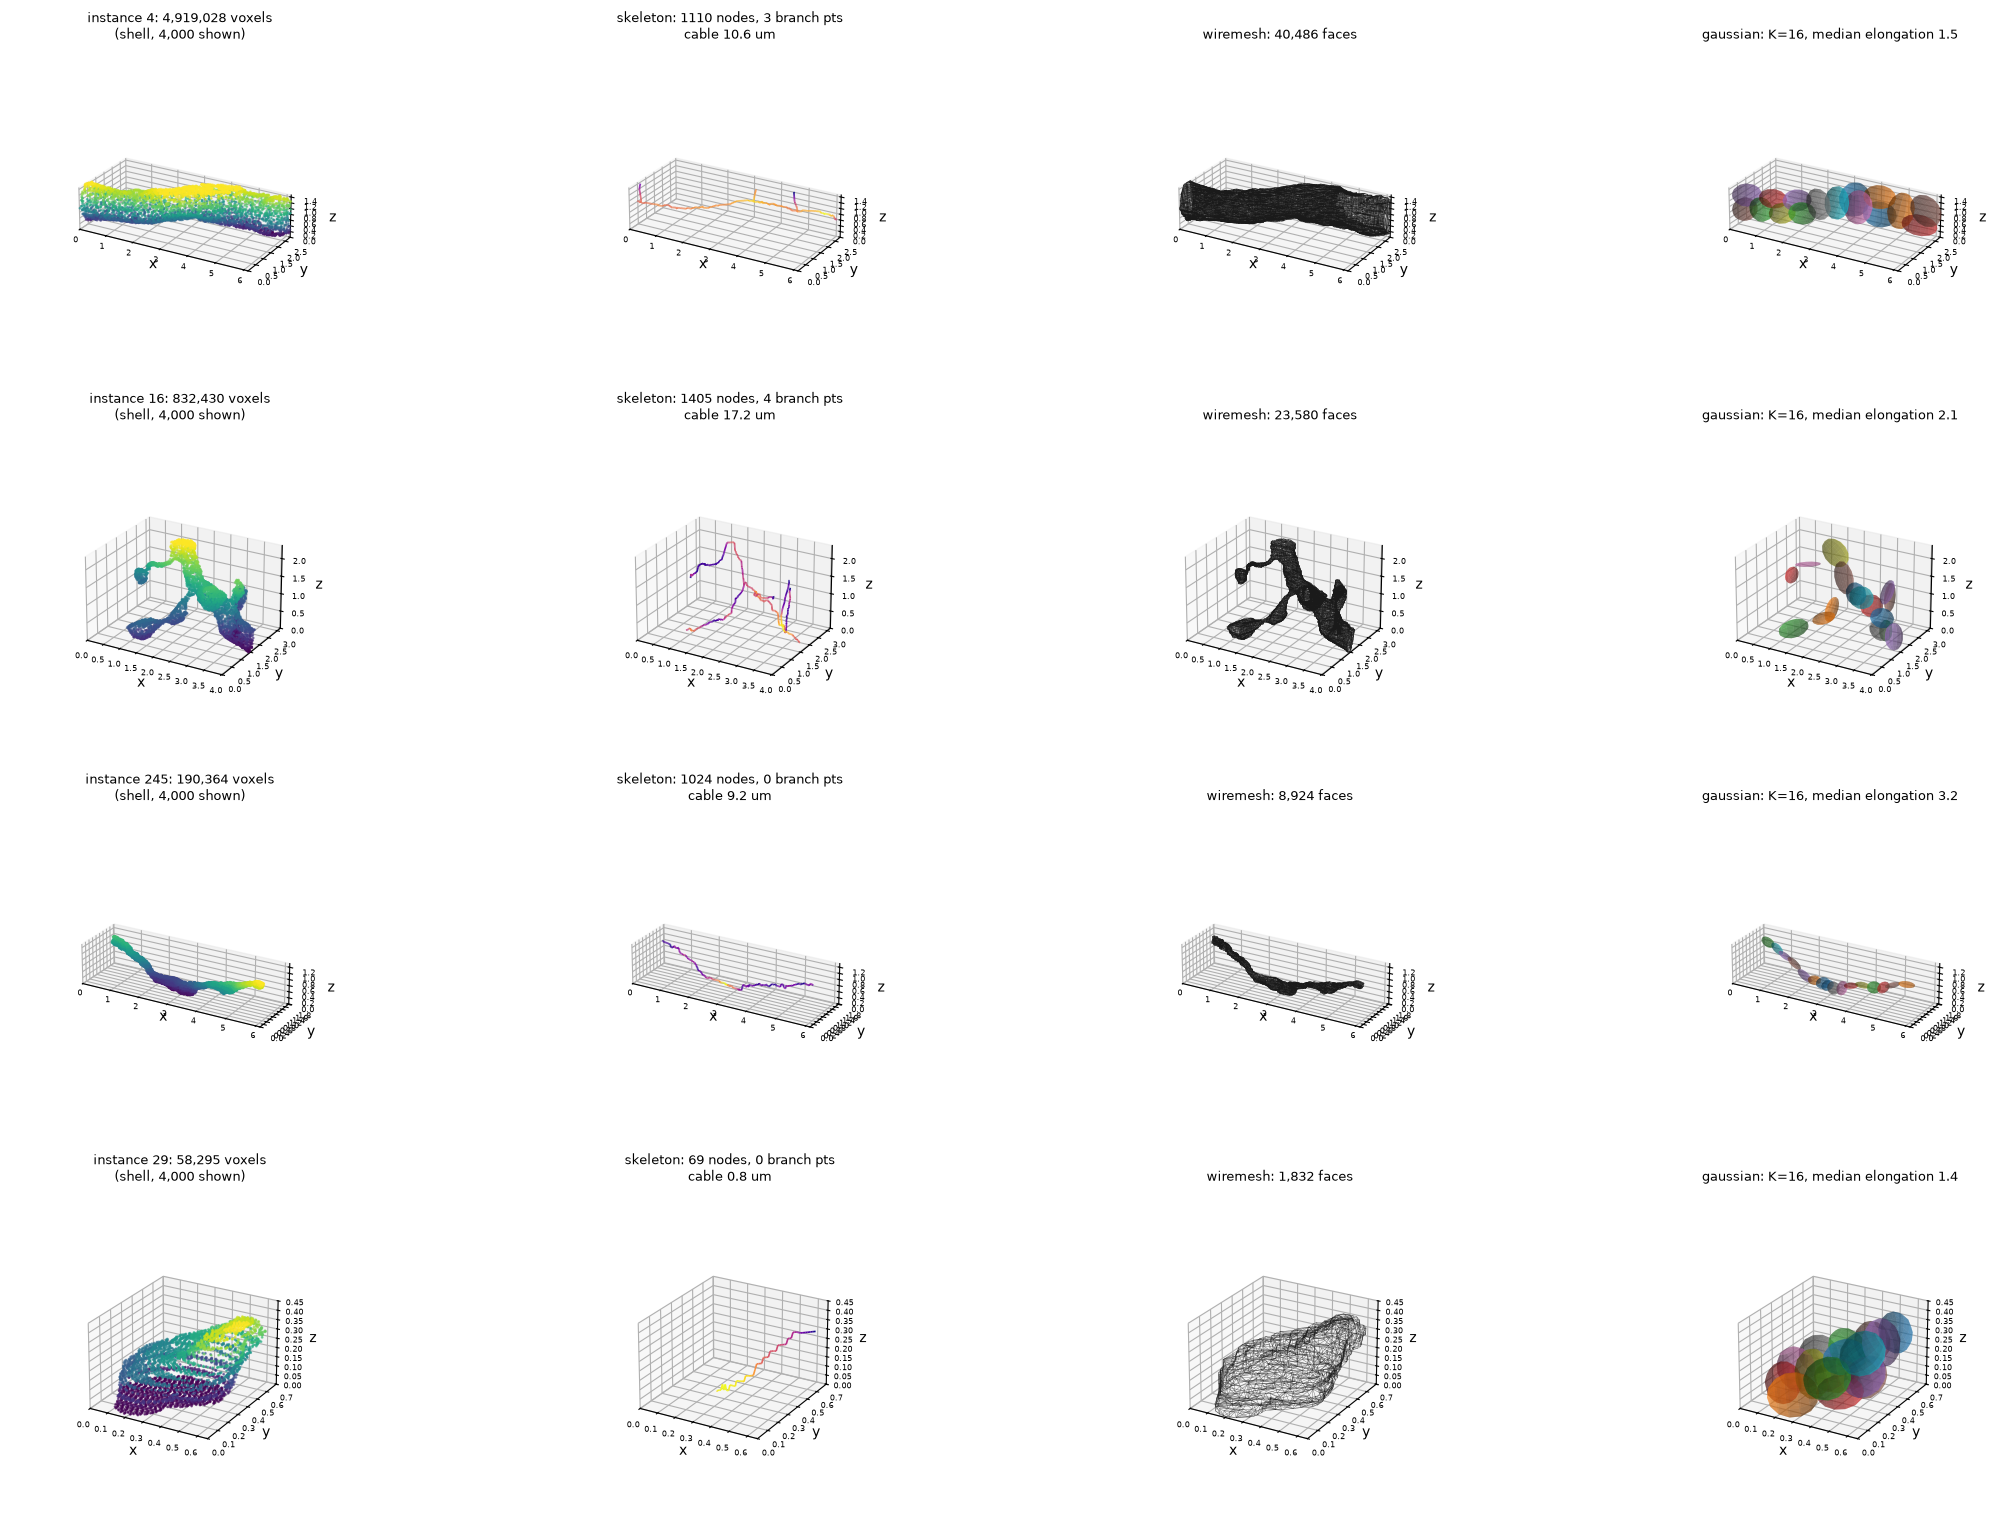

In [6]:
def set_box(ax, ext_um):
    ax.set_xlim(0, ext_um[0]); ax.set_ylim(0, ext_um[1]); ax.set_zlim(0, ext_um[2])
    ax.set_box_aspect(np.array(ext_um), zoom=0.62)   # a COPY: matplotlib normalises its argument in place; zoom 0.62 because a wide box overflows at 1
    ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z")
    ax.tick_params(labelsize=6)
    ax.view_init(elev=24, azim=-60)


def ellipsoid_surface(mu, cov, tau=TAU, n=14):
    w, V = np.linalg.eigh(cov)
    u, v = np.meshgrid(np.linspace(0, 2 * np.pi, n), np.linspace(0, np.pi, n // 2 + 1))
    sph = np.stack([np.cos(u) * np.sin(v), np.sin(u) * np.sin(v), np.cos(v)], -1)
    return mu + (sph * np.sqrt(tau * np.clip(w, 0, None))) @ V.T


def show_instance(axs, i):
    sub, grid, _ = crop_instance(i)
    br = C.instance_to_bricks(sub, grid, surface_only=True, max_bricks=4000, instance_id=i)
    sk = C.instance_to_skeleton(sub, grid, dust_nm3=0.0, instance_id=i)
    mesh = C.instance_to_mesh(sub, grid, simplify_factor=30, instance_id=i)
    g = C.instance_to_gaussians(sub, grid, k=16, instance_id=i)
    ext = grid.extent_xyz_nm / 1e3
    p = br.centers_xyz_nm / 1e3
    axs[0].scatter(*p.T, s=1.0, c=p[:, 2], cmap="viridis", alpha=0.6, depthshade=False)
    axs[0].set_title(f"instance {i}: {br.n_voxels_total:,} voxels\n(shell, {len(br):,} shown)", fontsize=9)
    v = sk.vertices_xyz_nm / 1e3
    segs = v[sk.edges]
    lc = Line3DCollection(segs, cmap="plasma", linewidths=1.2)
    lc.set_array(0.5 * (sk.radii_nm[sk.edges[:, 0]] + sk.radii_nm[sk.edges[:, 1]]))
    axs[1].add_collection3d(lc)
    axs[1].set_title(f"skeleton: {len(v)} nodes, {sk.n_branch_points()} branch pts\ncable {sk.cable_length_nm() / 1e3:.1f} um", fontsize=9)
    tri = mesh.vertices_xyz_nm[mesh.faces] / 1e3
    axs[2].add_collection3d(Poly3DCollection(tri, facecolors=(1, 1, 1, 0.0), edgecolors=(0.1, 0.1, 0.1, 0.5), linewidths=0.2))
    axs[2].set_title(f"wiremesh: {len(mesh.faces):,} faces", fontsize=9)
    for k, (mu, cov, col) in enumerate(zip(g.means_xyz_nm, g.covariances_nm2, g.colors_rgb)):
        s = ellipsoid_surface(mu / 1e3, cov / 1e6)
        axs[3].plot_surface(s[..., 0], s[..., 1], s[..., 2], color=col, alpha=0.45, linewidth=0, shade=True)
    axs[3].set_title(f"gaussian: K={len(g)}, median elongation {np.median(g.elongation()):.1f}", fontsize=9)
    for a in axs:
        set_box(a, ext)


fig = plt.figure(figsize=(22, 3.9 * len(SHOW_RANKS)))
for r_, rank in enumerate(SHOW_RANKS):
    if rank >= len(IDS):
        continue
    axs = [fig.add_subplot(len(SHOW_RANKS), 4, 4 * r_ + c + 1, projection="3d") for c in range(4)]
    show_instance(axs, int(IDS[rank]))
fig.subplots_adjust(left=0.0, right=1.0, top=0.95, bottom=0.0, wspace=0.0, hspace=0.12)
plt.show()

## 4. Skeleton insight

What the centre line says about a neuron: how long, how thick, how branched, and whether `volume ~ pi r^2 L` holds
(a neurite is a cable).

skeleton exists for 400 of 400 instances
cable length: total 2,006 um, median 3.74 um, max 62 um
mean radius along the cable: median 75 nm (middle 50%: 63-91 nm); voxel in-plane edge is 6 nm, section thickness 30 nm
raw cable / smoothed cable: median 1.25  (the chain of voxel centres over-states the length)
V / (pi r^2 L), instances > 0.05 um^3: median 1.56, middle 50% 1.43-1.75
log-log fit cable ~ volume^0.68 (r=0.87); a pure cylinder of fixed radius would be 1.0, a sphere 0.33
instances with no branch point at all: 59%; branch points per mm of cable: median 0; end points minus branch points per instance: median 2  (2 for one clean tree, more where nodes of degree >= 4 or several pieces exist)
skeleton drawn as balls of the node radius: median IoU 0.62, recall 0.62, precision 1.00  -> the radius is the INSCRIBED radius
   radius x 1.25: median IoU 0.71, precision 0.85
   radius x 1.5: median IoU 0.61, precision 0.66
   radius x 2.0: median IoU 0.40, precision 0.40


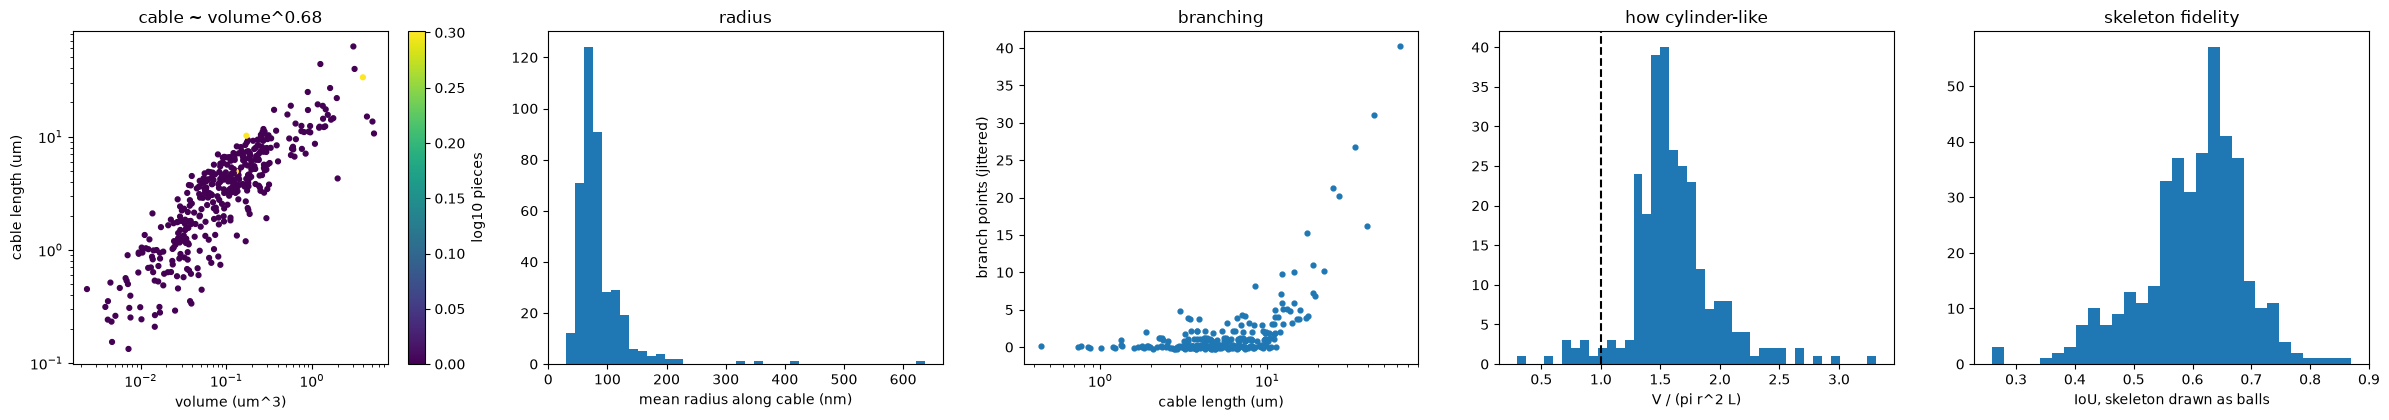

In [7]:
S = R.dropna(subset=["cable_nm"]).copy()
S["tortuosity_gain"] = S.cable_nm / S.cable_smooth_nm                      # raw zig-zag over-states length by this factor
S["cylinder_ratio"] = S.volume_nm3 / (np.pi * S.mean_radius_nm ** 2 * S.cable_nm)
S["branch_per_mm"] = S.n_branch / (S.cable_nm / 1e6)
S["radius_nm"] = S.mean_radius_nm
big = S[S.volume_um3 > 0.05]                                             # skip dust and tiny fragments for the ratios
print(f"skeleton exists for {len(S)} of {len(R)} instances")
print(f"cable length: total {S.cable_um.sum():,.0f} um, median {S.cable_um.median():.2f} um, max {S.cable_um.max():.0f} um")
print(f"mean radius along the cable: median {S.radius_nm.median():.0f} nm (middle 50%: {S.radius_nm.quantile(.25):.0f}-{S.radius_nm.quantile(.75):.0f} nm); "
      f"voxel in-plane edge is {min(vx, vy):g} nm, section thickness {vz:g} nm")
print(f"raw cable / smoothed cable: median {S.tortuosity_gain.median():.2f}  (the chain of voxel centres over-states the length)")
print(f"V / (pi r^2 L), instances > 0.05 um^3: median {big.cylinder_ratio.median():.2f}, middle 50% {big.cylinder_ratio.quantile(.25):.2f}-{big.cylinder_ratio.quantile(.75):.2f}")
sl, ic, rr, pv, _ = stats.linregress(np.log10(S.volume_um3), np.log10(S.cable_um))
print(f"log-log fit cable ~ volume^{sl:.2f} (r={rr:.2f}); a pure cylinder of fixed radius would be 1.0, a sphere 0.33")
print(f"instances with no branch point at all: {(big.n_branch == 0).mean():.0%}; branch points per mm of cable: median {big.branch_per_mm.median():.0f}; "
      f"end points minus branch points per instance: median {(S.n_end - S.n_branch).median():.0f}  (2 for one clean tree, "
      f"more where nodes of degree >= 4 or several pieces exist)")
print(f"skeleton drawn as balls of the node radius: median IoU {S.skel_ball_iou.median():.2f}, "
      f"recall {S.skel_ball_recall.median():.2f}, precision {S.skel_ball_precision.median():.2f}  -> the radius is the INSCRIBED radius")
for sc in BALL_SCALES:
    print(f"   radius x {sc}: median IoU {S[f'skel_ball{round(100 * sc)}_iou'].median():.2f}, "
          f"precision {S[f'skel_ball{round(100 * sc)}_precision'].median():.2f}")

fig, axs = plt.subplots(1, 5, figsize=(24, 4.3))
sc = axs[0].scatter(S.volume_um3, S.cable_um, c=np.log10(S.n_comp), s=12, cmap="viridis")
axs[0].set_xscale("log"); axs[0].set_yscale("log"); axs[0].set_xlabel("volume (um^3)"); axs[0].set_ylabel("cable length (um)")
axs[0].set_title(f"cable ~ volume^{sl:.2f}"); plt.colorbar(sc, ax=axs[0], label="log10 pieces")
axs[1].hist(S.radius_nm, bins=40); axs[1].set_xlabel("mean radius along cable (nm)"); axs[1].set_title("radius")
jit = np.random.default_rng(0).uniform(-0.25, 0.25, len(big))                # n_branch is an integer: jitter so points do not stack
axs[2].scatter(big.cable_um, big.n_branch + jit, s=12); axs[2].set_xscale("log")
axs[2].set_xlabel("cable length (um)"); axs[2].set_ylabel("branch points (jittered)"); axs[2].set_title("branching")
axs[3].hist(big.cylinder_ratio.clip(upper=4), bins=40); axs[3].axvline(1, c="k", ls="--")
axs[3].set_xlabel("V / (pi r^2 L)"); axs[3].set_title("how cylinder-like")
axs[4].hist(S.skel_ball_iou, bins=30); axs[4].set_xlabel("IoU, skeleton drawn as balls"); axs[4].set_title("skeleton fidelity")
fig.tight_layout(); plt.show()

## 5. Wiremesh insight

The mesh is a lossless description of the mask up to corner cutting, so the interesting numbers are: how much volume it
loses, how rough the surface is (area against the area of a sphere of the same volume; 1.0 is a sphere), and what
simplification buys.

meshes for 400 of 400 instances; faces: total 55,722,548, median 86,158, max 1,786,676
mesh volume / voxel volume: median 0.9975, range 0.9810-0.9999  (corner cutting)
surface area / area of the equal-volume sphere: median 2.5, max 5
faces per voxel: median 0.94
simplify_factor=10: faces x0.10 (median), volume change median -0.17 %, area change median -1.4 %
Euler check on single-piece instances: V - E + F should be 2 - 2 genus (even): 100.0% even


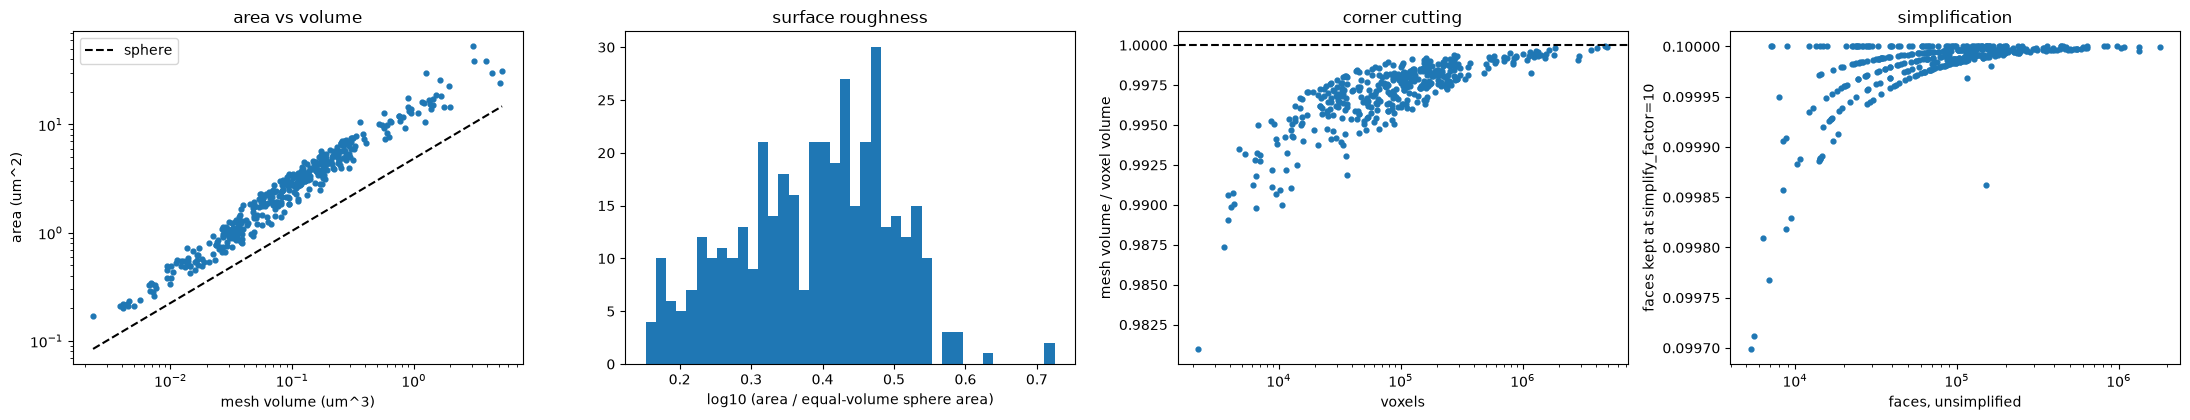

In [8]:
M = R.dropna(subset=["mesh_faces"]).copy()
M["vol_ratio"] = M.mesh_vol_nm3 / M.volume_nm3
M["area_um2"] = M.mesh_area_nm2 / 1e6
sphere_area = (36 * np.pi) ** (1 / 3) * M.mesh_vol_nm3 ** (2 / 3)
M["roughness"] = M.mesh_area_nm2 / sphere_area                           # 1 = sphere; neurites are far above
M["faces_per_vox"] = M.mesh_faces / M.n_vox
M["simp_vol_err"] = (M.mesh10_vol_nm3 / M.mesh_vol_nm3 - 1) * 100
M["simp_area_err"] = (M.mesh10_area_nm2 / M.mesh_area_nm2 - 1) * 100
print(f"meshes for {len(M)} of {len(R)} instances; faces: total {M.mesh_faces.sum():,}, median {int(M.mesh_faces.median()):,}, max {M.mesh_faces.max():,}")
print(f"mesh volume / voxel volume: median {M.vol_ratio.median():.4f}, range {M.vol_ratio.min():.4f}-{M.vol_ratio.max():.4f}  (corner cutting)")
print(f"surface area / area of the equal-volume sphere: median {M.roughness.median():.1f}, max {M.roughness.max():.0f}")
print(f"faces per voxel: median {M.faces_per_vox.median():.2f}")
ok = M.dropna(subset=["mesh10_faces"])
print(f"simplify_factor=10: faces x{(ok.mesh10_faces / ok.mesh_faces).median():.2f} (median), volume change median {ok.simp_vol_err.median():+.2f} %, "
      f"area change median {ok.simp_area_err.median():+.1f} %")
print(f"Euler check on single-piece instances: V - E + F should be 2 - 2 genus (even): "
      f"{((M[M.n_comp == 1].mesh_verts - M[M.n_comp == 1].mesh_edges + M[M.n_comp == 1].mesh_faces) % 2 == 0).mean():.1%} even")

fig, axs = plt.subplots(1, 4, figsize=(22, 4.3))
axs[0].scatter(M.mesh_vol_nm3 / 1e9, M.area_um2, s=12)
v_ = np.logspace(np.log10(M.mesh_vol_nm3.min() / 1e9), np.log10(M.mesh_vol_nm3.max() / 1e9), 50)
axs[0].plot(v_, (36 * np.pi) ** (1 / 3) * v_ ** (2 / 3), "k--", label="sphere")
axs[0].set_xscale("log"); axs[0].set_yscale("log"); axs[0].set_xlabel("mesh volume (um^3)"); axs[0].set_ylabel("area (um^2)")
axs[0].legend(); axs[0].set_title("area vs volume")
axs[1].hist(np.log10(M.roughness), bins=40); axs[1].set_xlabel("log10 (area / equal-volume sphere area)"); axs[1].set_title("surface roughness")
axs[2].scatter(M.n_vox, M.vol_ratio, s=12); axs[2].set_xscale("log"); axs[2].axhline(1, c="k", ls="--")
axs[2].set_xlabel("voxels"); axs[2].set_ylabel("mesh volume / voxel volume"); axs[2].set_title("corner cutting")
axs[3].scatter(ok.mesh_faces, ok.mesh10_faces / ok.mesh_faces, s=12); axs[3].set_xscale("log")
axs[3].set_xlabel("faces, unsimplified"); axs[3].set_ylabel("faces kept at simplify_factor=10"); axs[3].set_title("simplification")
fig.tight_layout(); plt.show()

## 6. Gaussian insight

### 6a. instance -> gaussian: how many Gaussians for how much overlap

IoU, recall and precision of the `TAU = 5` ellipsoid union against the instance for K = 1, 4, 16, 64, plus how
elongated the Gaussians are (longest / shortest standard deviation).

 K  n_inst  iou_median  iou_q25  iou_q75  recall  precision  elongation  seconds_median
 1     400       0.342    0.189    0.582   0.861      0.365       8.120           0.023
 4     400       0.667    0.562    0.732   0.885      0.730       3.333           0.095
16     400       0.770    0.740    0.802   0.899      0.843       1.568           0.235
64     400       0.822    0.803    0.857   0.913      0.893       1.373           0.649

median IoU by instance size quartile:
                K=1    K=4   K=16   K=64
n_vox                                   
smallest 25%  0.617  0.741  0.810  0.878
25-50%        0.354  0.683  0.770  0.823
50-75%        0.294  0.628  0.759  0.812
largest 25%   0.190  0.517  0.741  0.803


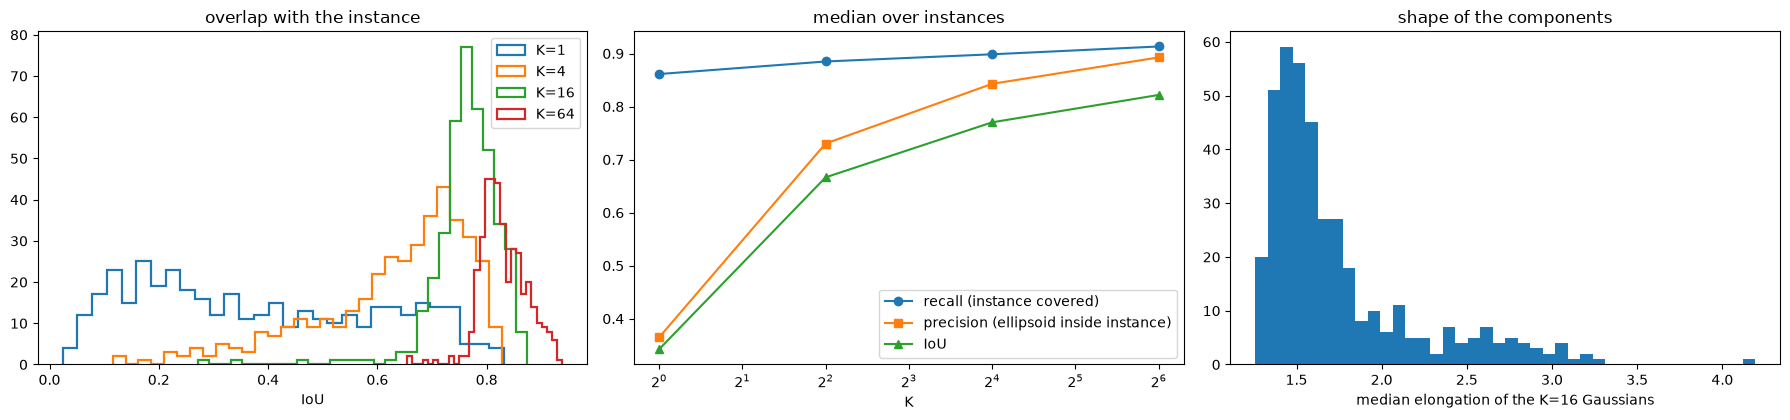

In [9]:
rows_ = []
for k in K_LIST:
    d = R.dropna(subset=[f"gauss{k}_iou"])
    rows_.append(dict(K=k, n_inst=len(d), iou_median=d[f"gauss{k}_iou"].median(), iou_q25=d[f"gauss{k}_iou"].quantile(.25),
                      iou_q75=d[f"gauss{k}_iou"].quantile(.75), recall=d[f"gauss{k}_recall"].median(),
                      precision=d[f"gauss{k}_precision"].median(), elongation=d[f"gauss{k}_elong_med"].median(),
                      seconds_median=d[f"t_gauss{k}"].median()))
print(pd.DataFrame(rows_).round(3).to_string(index=False))

# how many Gaussians does an instance need? K at which the median IoU stops improving is size dependent
sizes = pd.qcut(R.n_vox, 4, labels=["smallest 25%", "25-50%", "50-75%", "largest 25%"])
tab = pd.DataFrame({f"K={k}": R.groupby(sizes, observed=True)[f"gauss{k}_iou"].median() for k in K_LIST})
print("\nmedian IoU by instance size quartile:")
print(tab.round(3).to_string())

fig, axs = plt.subplots(1, 3, figsize=(18, 4.3))
for k in K_LIST:
    axs[0].hist(R[f"gauss{k}_iou"], bins=30, histtype="step", lw=1.6, label=f"K={k}")
axs[0].set_xlabel("IoU"); axs[0].set_title("overlap with the instance"); axs[0].legend()
axs[1].plot(K_LIST, [R[f"gauss{k}_recall"].median() for k in K_LIST], "o-", label="recall (instance covered)")
axs[1].plot(K_LIST, [R[f"gauss{k}_precision"].median() for k in K_LIST], "s-", label="precision (ellipsoid inside instance)")
axs[1].plot(K_LIST, [R[f"gauss{k}_iou"].median() for k in K_LIST], "^-", label="IoU")
axs[1].set_xscale("log", base=2); axs[1].set_xlabel("K"); axs[1].legend(); axs[1].set_title("median over instances")
axs[2].hist(R.gauss16_elong_med.dropna(), bins=40); axs[2].set_xlabel("median elongation of the K=16 Gaussians")
axs[2].set_title("shape of the components")
fig.tight_layout(); plt.show()

### 6b. skeleton -> gaussian versus instance -> gaussian

`skeleton_to_gaussians` (defined above) never looks at a voxel: it cuts the skeleton into pieces and moment-matches each
piece from its node positions and radii. `skeleton_x` is the same with every radius multiplied by `INFLATE`
(the skeleton radius is the inscribed radius, section 4). `voxel` is the usual voxel k-means with the **same** K as the
skeleton version produced, so any difference is the information source, not the count.

 K_target  K_actual_median  n_inst  skeleton_iou  skeleton_x_iou  voxel_iou  skeleton_recall  voxel_recall  skeleton_precision  voxel_precision  skeleton_wins  skeleton_x_wins
        4              4.0     400         0.489           0.588      0.686            0.535         0.887               0.930            0.748          0.042            0.142
       16             16.0     400         0.514           0.675      0.771            0.519         0.899               0.994            0.845          0.000            0.030
       64             64.0     400         0.561           0.706      0.822            0.561         0.913               0.998            0.892          0.000            0.005


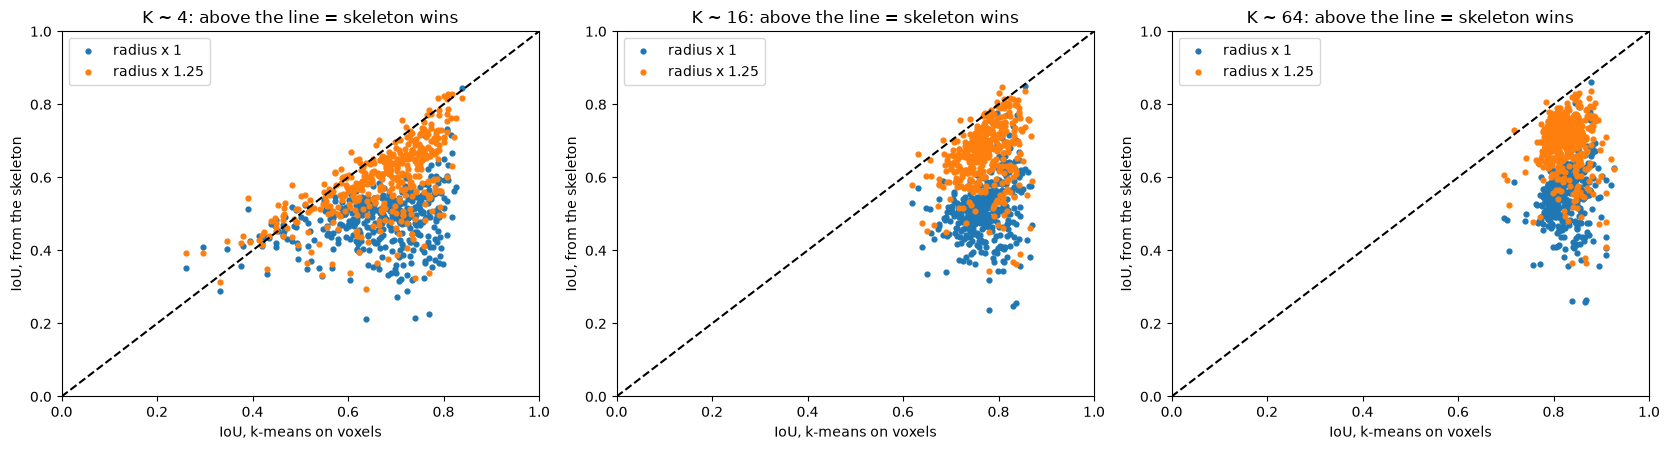

In [10]:
rows_ = []
for k in SKEL_K_LIST:
    d = R.dropna(subset=[f"sg{k}_iou"])
    rows_.append(dict(K_target=k, K_actual_median=d[f"sg{k}_n"].median(), n_inst=len(d),
                      skeleton_iou=d[f"sg{k}_iou"].median(), skeleton_x_iou=d[f"sgx{k}_iou"].median(), voxel_iou=d[f"vg{k}_iou"].median(),
                      skeleton_recall=d[f"sg{k}_recall"].median(), voxel_recall=d[f"vg{k}_recall"].median(),
                      skeleton_precision=d[f"sg{k}_precision"].median(), voxel_precision=d[f"vg{k}_precision"].median(),
                      skeleton_wins=(d[f"sg{k}_iou"] > d[f"vg{k}_iou"]).mean(),
                      skeleton_x_wins=(d[f"sgx{k}_iou"] > d[f"vg{k}_iou"]).mean()))
print(pd.DataFrame(rows_).round(3).to_string(index=False))

fig, axs = plt.subplots(1, len(SKEL_K_LIST), figsize=(5.6 * len(SKEL_K_LIST), 4.6))
for a, k in zip(np.atleast_1d(axs), SKEL_K_LIST):
    d = R.dropna(subset=[f"sg{k}_iou"])
    a.scatter(d[f"vg{k}_iou"], d[f"sg{k}_iou"], s=12, c="tab:blue", label="radius x 1")
    a.scatter(d[f"vg{k}_iou"], d[f"sgx{k}_iou"], s=12, c="tab:orange", label=f"radius x {INFLATE}"); a.legend()
    a.plot([0, 1], [0, 1], "k--"); a.set_xlim(0, 1); a.set_ylim(0, 1)
    a.set_xlabel("IoU, k-means on voxels"); a.set_ylabel("IoU, from the skeleton"); a.set_title(f"K ~ {k}: above the line = skeleton wins")
fig.tight_layout(); plt.show()

## 7. What ignoring anisotropy costs

The voxels are 6 x 6 x 30 nm: a pipeline that treats them as cubes (`grid.as_cubes()`) gets wrong lengths, areas and
Gaussian shapes. `compare_anisotropy` tabulates the first two for one instance; `gaussians_wrong_ways` gives four wrong
mixtures (wrong clustering, wrong covariance, or both), which we score with the same drawing and IoU as above.

In [11]:
i_demo = int(IDS[SHOW_RANKS[min(1, len(SHOW_RANKS) - 1)]])
sub, grid, _ = crop_instance(i_demo)
rows_ = C.compare_anisotropy(sub, grid)
aniso = {r_["quantity"]: r_["as_cubes_percent"] for r_ in rows_}
print(f"instance {i_demo}: {int(sub.sum()):,} voxels, grid {grid.describe()}\n")
print(pd.DataFrame(rows_).round(3).to_string(index=False))

ways = C.gaussians_wrong_ways(sub, grid, k=16)
res = {name: overlap(draw_gaussians(g, grid), sub) for name, g in ways.items()}
print("\nK = 16 mixtures, drawn on the true grid:")
print(pd.DataFrame(res).T.round(3).to_string())

instance 16: 832,430 voxels, grid 670 x 530 x 79 voxels (x, y, z) of 6 x 6 x 30 nm = 4.02 x 3.18 x 2.37 um, anisotropy 5:1

              quantity      correct     as_cubes  as_cubes_percent
            volume_nm3 8.990244e+08 1.798049e+08           -80.000
         mesh_area_nm2 1.436511e+07 7.217492e+06           -49.757
       mesh_volume_nm3 8.980833e+08 1.796167e+08           -80.000
       cable_length_nm 1.715890e+04 1.119710e+04           -34.745
cable_length_smooth_nm 1.355445e+04 9.620581e+03           -29.023
        mean_radius_nm 1.074860e+02 4.212900e+01           -60.805
       n_branch_points 4.000000e+00 5.000000e+00            25.000

K = 16 mixtures, drawn on the true grid:
                             iou  recall  precision
correct                    0.698   0.892      0.763
index_fit_scaled           0.217   0.223      0.886
index_fit_transformed      0.689   0.890      0.753
same_clusters_scaled       0.203   0.211      0.847
same_clusters_transformed  0.698   0.8

## 8. Cost versus fidelity

Storage as float32 / int32 per representation against the 1-bit mask of the instance's bounding box, and the time of
each conversion. Fidelity is IoU for skeleton (as balls) and gaussian, and the volume ratio for the wiremesh (which has
no drawing step).

                         median bytes  median x smaller than mask  fidelity (median)
mask bbox (1 bit/voxel)     232818.75                       1.000              1.000
wiremesh                   1550868.00                       0.149              0.997
wiremesh, simplify 10       155094.00                       1.491                NaN
skeleton                      6340.00                      38.486              0.616
gaussian K=16                  640.00                     363.779              0.770
gaussian K=64                 2560.00                      90.945              0.822

fidelity: wiremesh = volume / voxel volume; skeleton and gaussian = IoU of the drawn representation with the instance

conversion time (s), median / 95th percentile / max over instances:
               median    p95     max
skeleton        0.278  4.462  42.153
wiremesh        0.238  1.648   7.459
gaussian K=1    0.023  0.214   0.785
gaussian K=4    0.095  0.293   0.925
gaussian K=16   0.235  0.450   1

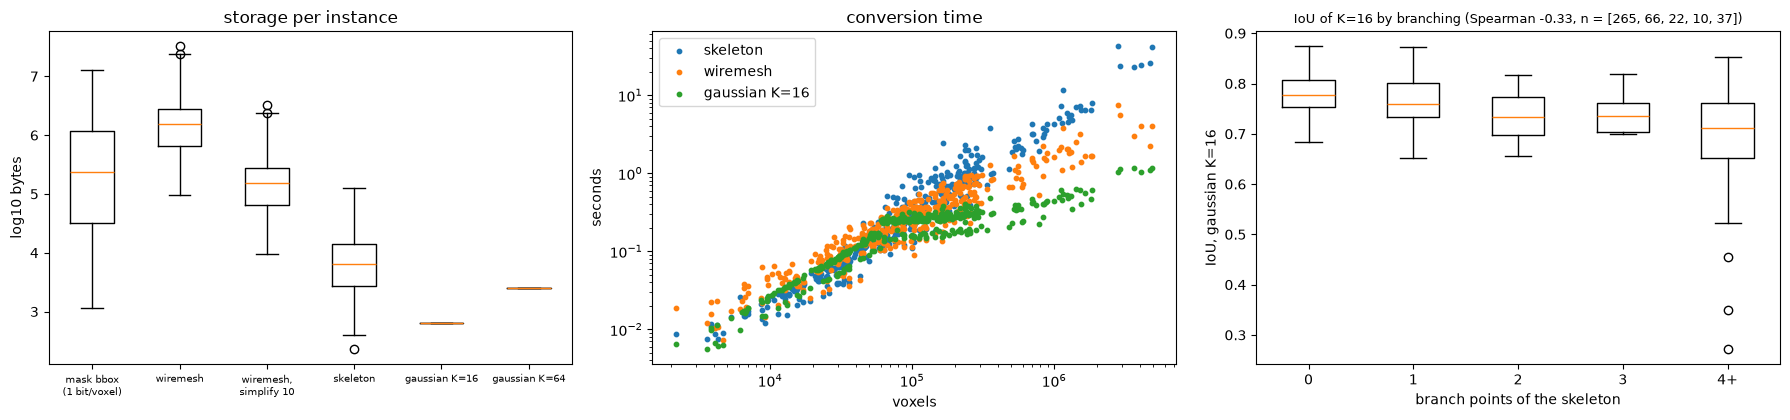

In [12]:
T = R.dropna(subset=["skel_bytes", "mesh_bytes"]).copy()
cmp_ = pd.DataFrame({
    "mask bbox (1 bit/voxel)": T.mask_bytes,
    "wiremesh": T.mesh_bytes,
    "wiremesh, simplify 10": T.mesh10_bytes,
    "skeleton": T.skel_bytes,
    "gaussian K=16": T.gauss16_bytes,
    "gaussian K=64": T.gauss64_bytes,
})
fid = {"mask bbox (1 bit/voxel)": 1.0, "wiremesh": M.vol_ratio.median(),
       "wiremesh, simplify 10": np.nan, "skeleton": T.skel_ball_iou.median(),
       "gaussian K=16": T.gauss16_iou.median(), "gaussian K=64": T.gauss64_iou.median()}
summary = pd.DataFrame({
    "median bytes": cmp_.median(),
    "median x smaller than mask": (cmp_.rdiv(cmp_["mask bbox (1 bit/voxel)"], axis=0).median()),
    "fidelity (median)": pd.Series(fid),
})
print(summary.round(3).to_string())
print("\nfidelity: wiremesh = volume / voxel volume; skeleton and gaussian = IoU of the drawn representation with the instance")

tcols = {"skeleton": "t_skel", "wiremesh": "t_mesh", **{f"gaussian K={k}": f"t_gauss{k}" for k in K_LIST}}
tt = pd.DataFrame({k: R[v] for k, v in tcols.items()})
print("\nconversion time (s), median / 95th percentile / max over instances:")
print(pd.DataFrame({"median": tt.median(), "p95": tt.quantile(.95), "max": tt.max()}).round(3).to_string())

fig, axs = plt.subplots(1, 3, figsize=(18, 4.3))
axs[0].boxplot([np.log10(cmp_[c]) for c in cmp_.columns], tick_labels=[c.replace(", ", ",\n").replace(" (", "\n(") for c in cmp_.columns])
axs[0].set_ylabel("log10 bytes"); axs[0].set_title("storage per instance"); axs[0].tick_params(axis="x", labelsize=7)
axs[1].scatter(R.n_vox, R.t_skel, s=10, label="skeleton"); axs[1].scatter(R.n_vox, R.t_mesh, s=10, label="wiremesh")
axs[1].scatter(R.n_vox, R.t_gauss16, s=10, label="gaussian K=16")
axs[1].set_xscale("log"); axs[1].set_yscale("log"); axs[1].set_xlabel("voxels"); axs[1].set_ylabel("seconds"); axs[1].legend()
axs[1].set_title("conversion time")
branchy = R.dropna(subset=["n_branch"])
rho, p = stats.spearmanr(branchy.n_branch, branchy.gauss16_iou)
grp = branchy.n_branch.clip(upper=4).astype(int)                                  # 4 = 4 or more
levels = sorted(grp.unique())
axs[2].boxplot([branchy.gauss16_iou[grp == g_] for g_ in levels],
               tick_labels=[f"{g_}" if g_ < 4 else "4+" for g_ in levels])
axs[2].set_xlabel("branch points of the skeleton"); axs[2].set_ylabel("IoU, gaussian K=16")
axs[2].set_title(f"IoU of K=16 by branching (Spearman {rho:.2f}, n = {[int((grp == g_).sum()) for g_ in levels]})", fontsize=9)
fig.tight_layout(); plt.show()

## 9. Progression: `voxel -> frame -> graph`, each rendered from `wiremesh` to `gaussian`

The structural representations form a two-axis grid:

* **Horizontal progression (`voxel -> frame -> graph`)** strips away interior degrees of freedom step by step:
  1. **Voxel** (`Bricks`, 3D occupancy lattice): every 6 x 6 x 30 nm voxel on the shell is kept.
  2. **Frame** (`Mesh`, 2D boundary scaffold): marching-cubes surface frame enclosing the volume without interior voxels.
  3. **Graph** (`Skeleton`, 1D topological tree): centreline nodes `(x, y, z, r)` and edges with branch / end topology.

* **Vertical rendering dual (`wiremesh <-> gaussian`)** shows that **every stage** along `voxel -> frame -> graph` has both a discrete polygonal **wiremesh** form and a continuous **3D Gaussian** form (ray-cast on GPU with `ncntm.viz.emray`):
  * `voxel`: exposed brick quad wires <-> one `6 x 6 x 30 nm` anisotropic box-variance Gaussian per shell voxel (`voxel_gaussian`).
  * `frame`: surface triangle wires <-> one tangent plate Gaussian per triangle face (in-plane triangle moment `(1/12) sum (v_j - mu)(v_j - mu)^T` + thin normal shell).
  * `graph`: tubular cage wires + branch spheres <-> one oriented cylinder Gaussian per graph edge (axial `L^2/12`, radial `r^2/5`).

Warp 1.19.0 initialized:
   CUDA Toolkit 13.4, Driver 13.5
   Devices:
     "cpu"      : "CPU"
     "cuda:0"   : "NVIDIA Graphics Device" (248 GiB, sm_107, mempool enabled)
     "cuda:1"   : "NVIDIA Graphics Device" (248 GiB, sm_107, mempool enabled)
     "cuda:2"   : "NVIDIA Graphics Device" (248 GiB, sm_107, mempool enabled)
     "cuda:3"   : "NVIDIA Graphics Device" (248 GiB, sm_107, mempool enabled)
     "cuda:4"   : "NVIDIA Graphics Device" (248 GiB, sm_107, mempool enabled)
     "cuda:5"   : "NVIDIA Graphics Device" (248 GiB, sm_107, mempool enabled)
     "cuda:6"   : "NVIDIA Graphics Device" (248 GiB, sm_107, mempool enabled)
     "cuda:7"   : "NVIDIA Graphics Device" (248 GiB, sm_107, mempool enabled)
   CUDA peer access:
     Supported fully (all-directional)
   Kernel cache:
     /home/nvidia/.cache/warp/1.19.0
Module ncntm.viz.emray 971ec07 load on device 'cuda:0' took 6.86 ms  (cached)
primitive counts along voxel -> frame -> graph (full instance): {'bricks': 165940, 'faces

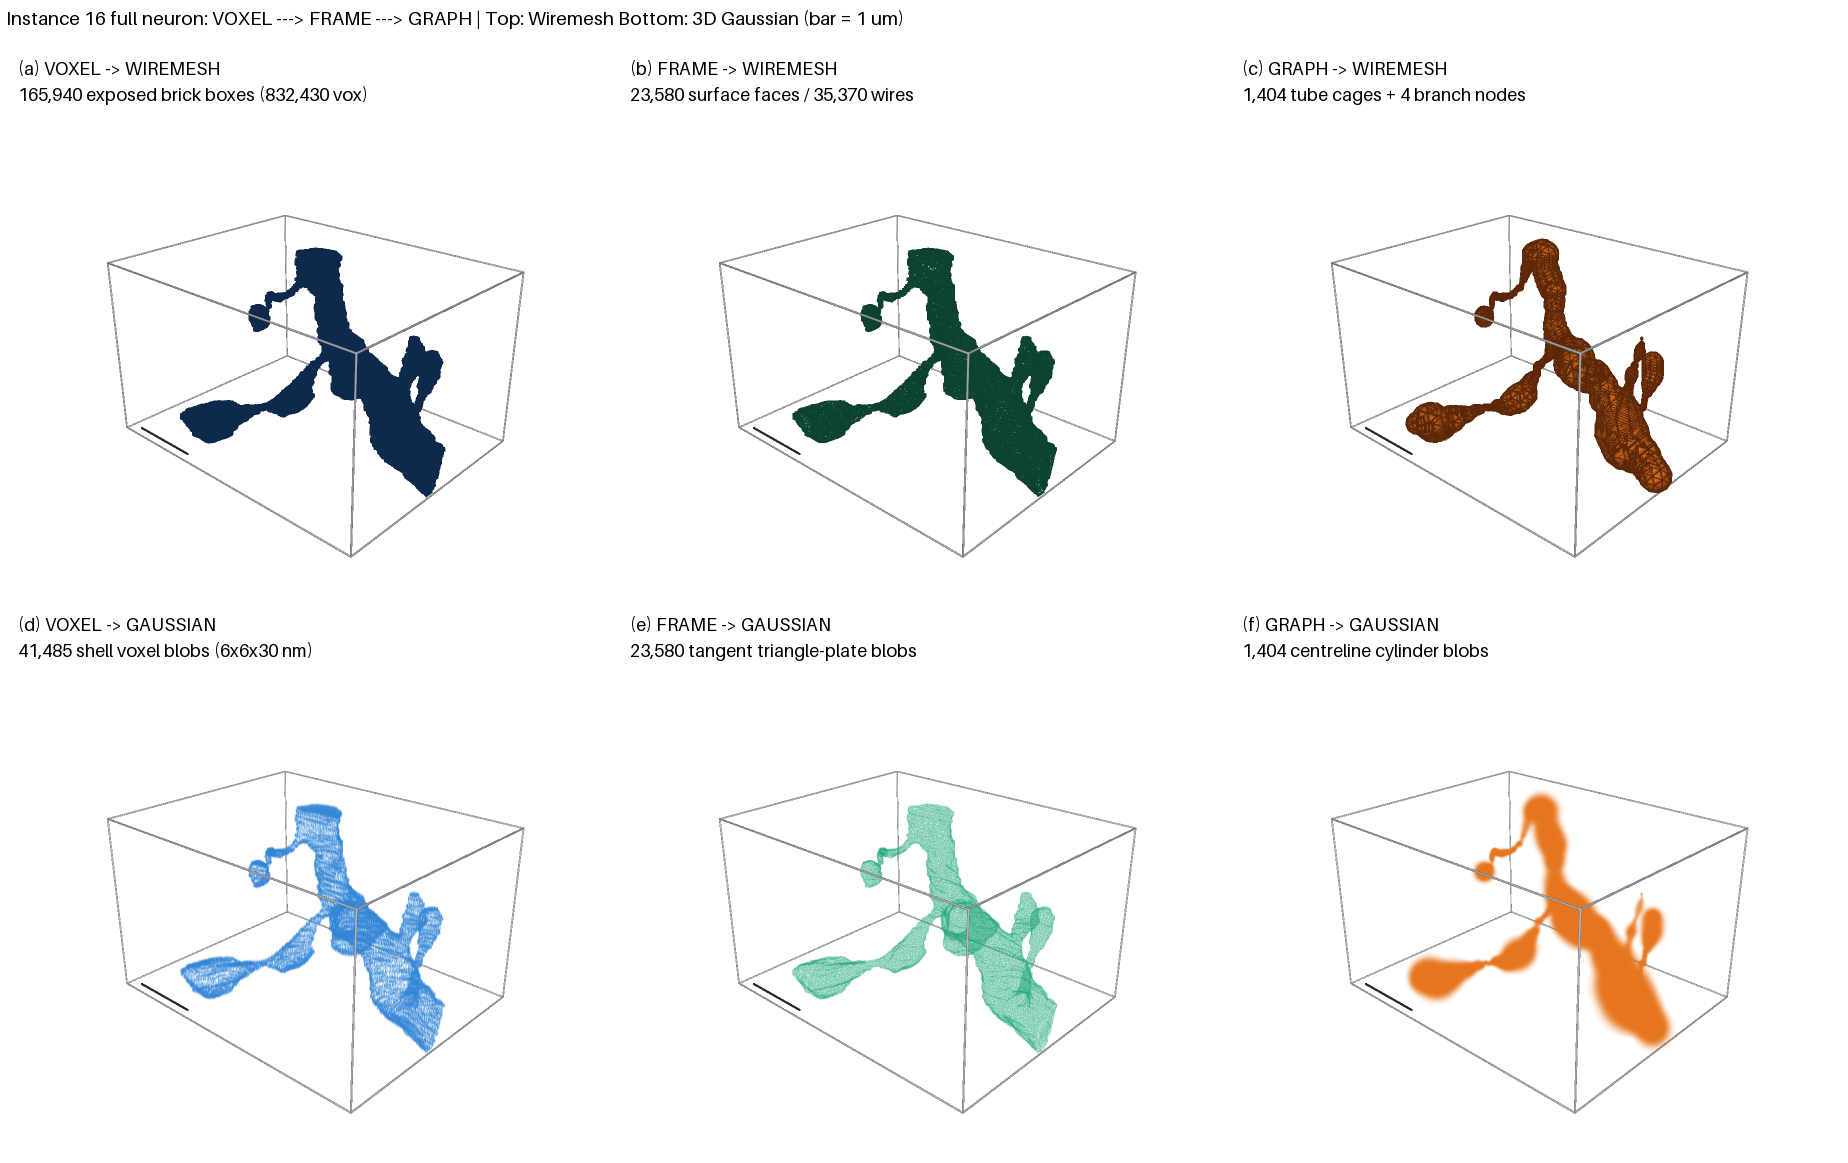

In [13]:
from ncntm.viz import emray, figure
from ncntm.viz.grid import NM_PER_UNIT

emray.load_kernels()


def face_gaussians(mesh, shell_nm=6.0):
    # Frame -> Gaussian: each triangle of the surface frame becomes one tangent Gaussian plate.
    tri = mesh.vertices_xyz_nm[mesh.faces]
    mu = tri.mean(axis=1)
    d = tri - mu[:, None, :]
    cov = np.einsum("fja,fjb->fab", d, d) / 12.0
    nrm = np.cross(tri[:, 1] - tri[:, 0], tri[:, 2] - tri[:, 0])
    area = 0.5 * np.linalg.norm(nrm, axis=1)
    nrm = nrm / np.maximum(2.0 * area[:, None], 1e-12)
    cov = cov + (shell_nm ** 2 / 12.0) * np.einsum("fa,fb->fab", nrm, nrm) + 1.0 * np.eye(3)[None]
    w = np.maximum(area, 1e-9)
    return Gaussians(mu, cov, w / w.sum(), instance_id=mesh.instance_id)


def edge_gaussians(sk, radius_scale=INFLATE):
    # Graph -> Gaussian: each skeleton edge becomes one cylinder-moment Gaussian aligned with the edge.
    pts, edges = sk.vertices_xyz_nm, sk.edges
    p0, p1 = pts[edges[:, 0]], pts[edges[:, 1]]
    mu = 0.5 * (p0 + p1)
    d = p1 - p0
    Le = np.linalg.norm(d, axis=1)
    u = d / np.maximum(Le[:, None], 1e-12)
    r = 0.5 * (sk.radii_nm[edges[:, 0]] + sk.radii_nm[edges[:, 1]]) * radius_scale
    uu = np.einsum("ea,eb->eab", u, u)
    cov = (Le ** 2 / 12.0 + (0.35 * r) ** 2)[:, None, None] * uu + (r ** 2 / 5.0)[:, None, None] * (np.eye(3)[None] - uu)
    w = np.pi * r ** 2 * np.maximum(Le, 1.0)
    return Gaussians(mu, cov, w / w.sum(), instance_id=sk.instance_id)


def render_progression_matrix(mask, grid, mesh_simplify=25, max_voxel_blobs=35_000, bar_um=1.0, title=""):
    lo, hi = np.zeros(3), grid.extent_xyz_nm / NM_PER_UNIT
    cam = emray.Camera.fit(lo, hi, direction=(1.05, -1.15, 0.72), width=600, height=480, ssaa=2)
    br = C.instance_to_bricks(mask, grid, surface_only=True)
    me = C.instance_to_mesh(mask, grid, simplify_factor=mesh_simplify)
    sk = C.instance_to_skeleton(mask, grid, dust_nm3=0.0)

    col_vox, col_frm, col_grp = (0.20, 0.52, 0.84), (0.14, 0.66, 0.48), (0.90, 0.46, 0.12)

    def blank():
        s = emray.Scene()
        s.add_wire_box(lo, hi, color=(0.76, 0.78, 0.82), min_pixels=1.0)
        s.add_scale_bar(lo + np.array([0.04 * (hi[0] - lo[0]), 0.04 * (hi[1] - lo[1]), 0.0]),
                        (1, 0, 0), bar_um, color=(0.15, 0.15, 0.15), min_pixels=2.2)
        return s

    # Top row: WIREMESH across Voxel -> Frame -> Graph
    s = blank()
    s.add_bricks(br, grid, color=(*col_vox, 0.86), wire_color=(0.06, 0.16, 0.30, 1.0), wire_min_pixels=0.9)
    p_vw = s.render(cam, hemisphere=0.35)

    s = blank()
    s.add_wiremesh(me, grid, color=(*col_frm, 0.22), wire_color=(0.05, 0.26, 0.18, 1.0), wire_min_pixels=1.1)
    p_fw = s.render(cam, hemisphere=0.35, max_hits=12)

    s = blank()
    s.add_skeleton(sk, grid, radius=sk.radii_nm * INFLATE / NM_PER_UNIT, color=(*col_grp, 0.25),
                   wire_color=(0.36, 0.15, 0.03, 1.0), wire_min_pixels=1.0)
    s.add_tubes(sk.vertices_xyz_nm / NM_PER_UNIT, sk.edges, 0.008 * bar_um, caps="round", color=(0.20, 0.08, 0.02, 1.0))
    deg = sk.degrees()
    if (deg > 2).any():
        s.add_spheres(sk.vertices_xyz_nm[deg > 2] / NM_PER_UNIT,
                      sk.radii_nm[deg > 2] / NM_PER_UNIT * 0.6, color=(0.86, 0.12, 0.16))
    p_gw = s.render(cam, hemisphere=0.35, max_hits=12)

    # Bottom row: 3D GAUSSIAN across Voxel -> Frame -> Graph
    step = max(1, len(br) // max_voxel_blobs)
    vg = C.voxel_gaussian(grid, br.kji[::step], scale=2.4)
    s = blank(); s.add_gaussian_mixture(vg, grid, opacity=0.54, color=col_vox)
    p_vg = s.render(cam)

    fg = face_gaussians(me)
    s = blank(); s.add_gaussian_mixture(fg, grid, opacity=0.45, color=col_frm)
    p_fg = s.render(cam)

    gg = edge_gaussians(sk)
    s = blank(); s.add_gaussian_mixture(gg, grid, opacity=0.58, color=col_grp)
    p_gg = s.render(cam)

    caps = [
        f"VOXEL -> WIREMESH\n{len(br):,} exposed brick boxes ({br.n_voxels_total:,} vox)",
        f"FRAME -> WIREMESH\n{len(me.faces):,} surface faces / {len(me.edges()):,} wires",
        f"GRAPH -> WIREMESH\n{len(sk.edges):,} tube cages + {sk.n_branch_points()} branch nodes",
        f"VOXEL -> GAUSSIAN\n{len(vg):,} shell voxel blobs (6x6x30 nm)",
        f"FRAME -> GAUSSIAN\n{len(fg):,} tangent triangle-plate blobs",
        f"GRAPH -> GAUSSIAN\n{len(gg):,} centreline cylinder blobs",
    ]
    pic = figure.montage([p_vw, p_fw, p_gw, p_vg, p_fg, p_gg], captions=caps, ncols=3, pad=12, labels=True)
    return figure.caption(pic, title, size=19), dict(bricks=len(br), faces=len(me.faces), edges=len(sk.edges),
                                                     vg=len(vg), fg=len(fg), gg=len(gg))


# Full branched neuron (instance i_demo)
sub_demo, grid_demo, _ = crop_instance(i_demo)
pic_full, counts_full = render_progression_matrix(
    sub_demo, grid_demo, mesh_simplify=25, bar_um=1.0,
    title=f"Instance {i_demo} full neuron: VOXEL  --->  FRAME  --->  GRAPH   |   Top: Wiremesh   Bottom: 3D Gaussian   (bar = 1 um)",
)
print("primitive counts along voxel -> frame -> graph (full instance):", counts_full)
figure.show(pic_full)

primitive counts in the junction cube: {'bricks': 35003, 'faces': 8196, 'edges': 301, 'vg': 35003, 'fg': 8196, 'gg': 301}


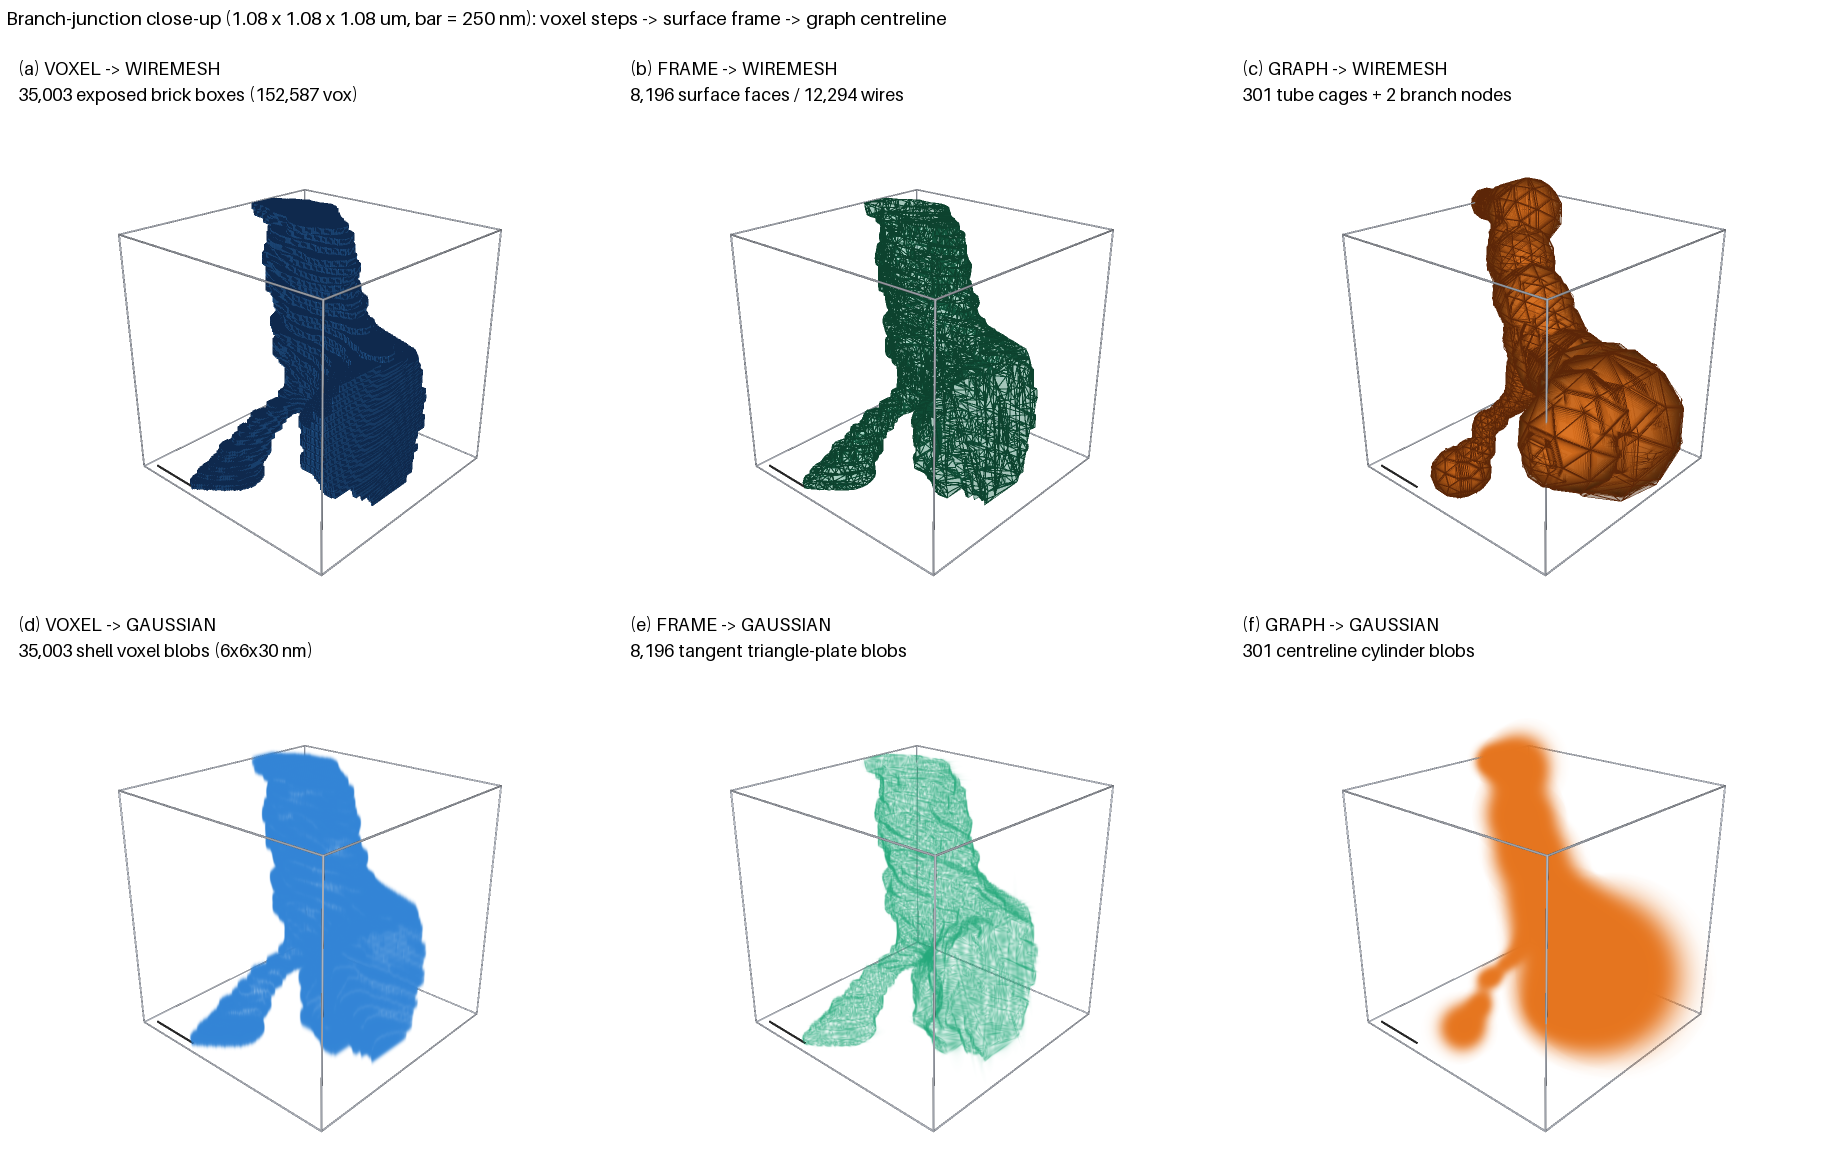

In [14]:
# Zoom into a 1.08 x 1.08 x 1.08 um cube around a branch junction so individual voxel bricks, mesh triangles,
# graph centreline cages and anisotropic Gaussian blobs are all resolved side by side.
sk_demo = C.instance_to_skeleton(sub_demo, grid_demo, dust_nm3=0.0)
bp_nm = sk_demo.vertices_xyz_nm[sk_demo.degrees() > 2][0]
bp_kji = grid_demo.nm_to_voxel(bp_nm)
k0, j0, i0 = [max(0, int(c - h)) for c, h in zip(bp_kji, (18, 90, 90))]
k1, j1, i1 = [min(n, k + w) for k, w, n in zip((k0, j0, i0), (36, 180, 180), sub_demo.shape)]
zoom_mask = sub_demo[k0:k1, j0:j1, i0:i1]
zoom_grid = VoxelGrid(zoom_mask.shape, VOX_ZYX)

pic_zoom, counts_zoom = render_progression_matrix(
    zoom_mask, zoom_grid, mesh_simplify=12, max_voxel_blobs=50_000, bar_um=0.25,
    title="Branch-junction close-up (1.08 x 1.08 x 1.08 um, bar = 250 nm): voxel steps -> surface frame -> graph centreline",
)
print("primitive counts in the junction cube:", counts_zoom)
figure.show(pic_zoom)

## 10. Special session: optimizing the number of Gaussian blobs (least blobs for similar Gaussian values)

Moving from `voxel` (33k blobs) to `frame` (24k) to `graph` (1.4k) already cuts the primitive count by 24x, **but a straight neurite segment still gets dozens of tiny Gaussians** because skeleton nodes sit one voxel apart and `instance_to_gaussians` uses Euclidean k-means (which splits long tubes into roughly isotropic chunks).

### Problem statement
Given a dense reference 3D Gaussian mixture $f_{\text{ref}}(x) = \sum_{m=1}^{M} w_m \mathcal{N}(x \mid \mu_m, \Sigma_m)$ ($M = 128$ or $256$ blobs), find the **smallest number of blobs $K^\star$** whose continuous 3D Gaussian field $f_K(x)$ achieves at least a target field similarity

$$\text{sim}_{L_2}(f_K, f_{\text{ref}}) \;=\; \frac{\langle f_K, f_{\text{ref}} \rangle_{L_2}}{\|f_K\|_{L_2}\,\|f_{\text{ref}}\|_{L_2}} \;\ge\; \tau_{\text{sim}}, \qquad \langle f, g \rangle_{L_2} = \int_{\mathbb{R}^3} f(x)\,g(x)\,dx = \sum_{i,j} w_i \tilde{w}_j \,\mathcal{N}\!\left(\mu_i \;\middle|\; \tilde{\mu}_j,\, \Sigma_i + \tilde{\Sigma}_j\right).$$

The inner product has an **exact closed form** (no Monte-Carlo or grid sampling noise).

### Three ways to place $K$ Gaussians
1. **Voxel k-means** (`instance_to_gaussians`): Euclidean Voronoi cells in nm. Wastes blobs on thick trunks and chops thin cylinders into beads.
2. **Greedy KL-moment merging** (Runnalls 2007): start from the dense mixture $f_{\text{ref}}$ and repeatedly merge the pair $(i, j)$ with the smallest upper bound on the KL divergence increment
   $$B(i, j) = \tfrac{1}{2}\Big[(w_i + w_j)\log|\Sigma_{ij}| - w_i\log|\Sigma_i| - w_j\log|\Sigma_j|\Big],$$
   where $(w_{ij}, \mu_{ij}, \Sigma_{ij})$ matches the exact 0th, 1st and 2nd moments of the pair. Collinear blobs along a straight branch merge at near-zero determinant growth; blobs across a bend or branch junction incur a large determinant jump and stay separate. One $O(M^2)$ sweep yields the **entire** optimal hierarchy $K = M, M-1, \dots, 1$.
3. **KL-merge + anisotropic full-covariance EM**: warm-start full-covariance Expectation-Maximization from the KL-merged mixture at budget $K$ (keeping the physical box-voxel floor $\text{diag}(dx^2, dy^2, dz^2)/12$), letting elongated ellipsoids slide and stretch cleanly along whole neurite branches.

In [15]:
LOG_2PI_3 = 3.0 * np.log(2.0 * np.pi)
SIM_TARGET = 0.85          # target L2 cosine similarity against the dense M=128 Gaussian field
M_REF = 128                # dense reference blob count per neuron


def gaussian_l2_inner(a: Gaussians, b: Gaussians) -> float:
    # Exact closed-form L2 inner product integral f_a(x) f_b(x) dx over R^3 via batch 3x3 Cholesky.
    d = a.means_xyz_nm[:, None, :] - b.means_xyz_nm[None, :, :]
    S = a.covariances_nm2[:, None, :, :] + b.covariances_nm2[None, :, :, :]
    Lc = np.linalg.cholesky(S)
    ld = 2.0 * np.log(np.diagonal(Lc, axis1=-2, axis2=-1)).sum(-1)
    y = np.linalg.solve(Lc, d[..., None])[..., 0]
    q = (y * y).sum(-1)
    return float((a.weights[:, None] * b.weights[None, :] * np.exp(-0.5 * (LOG_2PI_3 + ld + q))).sum())


def gaussian_l2_similarity(g: Gaussians, g_ref: Gaussians, norm_ref_sq: float = None) -> float:
    if norm_ref_sq is None:
        norm_ref_sq = gaussian_l2_inner(g_ref, g_ref)
    ip = gaussian_l2_inner(g, g_ref)
    n1 = gaussian_l2_inner(g, g)
    return float(ip / np.sqrt(max(n1 * norm_ref_sq, 1e-60)))


def kl_merge_hierarchy(g_dense: Gaussians) -> dict:
    # Runnalls (2007) greedy KL-bound reduction: returns {K: Gaussians} for ALL K in 1..len(g_dense) in one pass,
    # plus the merge cost curve so we can see the elbow where branches are forced to merge.
    mu = g_dense.means_xyz_nm.astype(np.float64).copy()
    cov = g_dense.covariances_nm2.astype(np.float64).copy()
    w = g_dense.weights.astype(np.float64).copy()
    n = len(w)
    _, logdet = np.linalg.slogdet(cov)
    alive = np.ones(n, dtype=bool)
    cost = np.full((n, n), np.inf)
    for a in range(n - 1):
        js = np.arange(a + 1, n)
        wij = w[a] + w[js]
        d = mu[a][None, :] - mu[js]
        cij = (w[a] * cov[a][None] + w[js, None, None] * cov[js]
               + (w[a] * w[js] / wij)[:, None, None] * np.einsum("ni,nj->nij", d, d)) / wij[:, None, None]
        _, ldij = np.linalg.slogdet(cij)
        cost[a, js] = 0.5 * (wij * ldij - w[a] * logdet[a] - w[js] * logdet[js])
    palette = C.PALETTE_RGB
    snaps = {n: Gaussians(mu.copy(), cov.copy(), w.copy(), palette[np.arange(n) % len(palette)], g_dense.instance_id)}
    step_costs = {}
    for cur_k in range(n - 1, 0, -1):
        ia, ja = divmod(int(np.argmin(cost)), n)
        step_costs[cur_k] = float(cost[ia, ja])
        wij = w[ia] + w[ja]
        d = mu[ia] - mu[ja]
        cij = (w[ia] * cov[ia] + w[ja] * cov[ja] + (w[ia] * w[ja] / wij) * np.outer(d, d)) / wij
        mu[ia] = (w[ia] * mu[ia] + w[ja] * mu[ja]) / wij
        cov[ia], w[ia] = cij, wij
        _, logdet[ia] = np.linalg.slogdet(cij)
        alive[ja] = False
        cost[ja, :] = cost[:, ja] = cost[ia, :] = cost[:, ia] = np.inf
        others = np.flatnonzero(alive)
        others = others[others != ia]
        if len(others):
            w_o = w[others]
            wij_o = w[ia] + w_o
            d_o = mu[ia][None, :] - mu[others]
            c_o = (w[ia] * cov[ia][None] + w_o[:, None, None] * cov[others]
                   + (w[ia] * w_o / wij_o)[:, None, None] * np.einsum("ni,nj->nij", d_o, d_o)) / wij_o[:, None, None]
            _, ld_o = np.linalg.slogdet(c_o)
            cost[np.minimum(ia, others), np.maximum(ia, others)] = 0.5 * (wij_o * ld_o - w[ia] * logdet[ia] - w_o * logdet[others])
        keep = np.flatnonzero(alive)
        snaps[cur_k] = Gaussians(mu[keep].copy(), cov[keep].copy(), w[keep].copy(),
                                 palette[np.arange(cur_k) % len(palette)], g_dense.instance_id)
    snaps["_step_costs"] = step_costs
    return snaps


def em_anisotropic_gmm(pts_nm: np.ndarray, vox_xyz_nm: np.ndarray, init_g: Gaussians, n_iter: int = 15) -> Gaussians:
    # Full-covariance EM over physical voxel centres with exact within-voxel box floor diag(dx^2, dy^2, dz^2)/12.
    n = len(pts_nm)
    reg = np.diag(np.asarray(vox_xyz_nm, float) ** 2 / 12.0)
    mu = init_g.means_xyz_nm.astype(np.float64).copy()
    cov = init_g.covariances_nm2.astype(np.float64).copy()
    w = init_g.weights.astype(np.float64).copy()
    k = len(w)
    for _ in range(n_iter):
        prec = np.linalg.inv(cov)
        _, ld = np.linalg.slogdet(cov)
        logp = np.empty((n, k))
        for j in range(k):
            d = pts_nm - mu[j]
            logp[:, j] = np.log(max(w[j], 1e-15)) - 0.5 * ld[j] - 0.5 * np.einsum("ni,ij,nj->n", d, prec[j], d)
        mx = logp.max(axis=1, keepdims=True)
        resp = np.exp(logp - mx)
        resp /= resp.sum(axis=1, keepdims=True)
        nk = resp.sum(axis=0)
        alive = nk > 2.0
        if not alive.all():
            resp, nk, k = resp[:, alive], nk[alive], int(alive.sum())
        w = nk / n
        mu = (resp.T @ pts_nm) / nk[:, None]
        cov = np.empty((k, 3, 3))
        for j in range(k):
            d = pts_nm - mu[j]
            cov[j] = (d.T * resp[:, j]) @ d / nk[j] + reg
    palette = C.PALETTE_RGB
    return Gaussians(mu, cov, w, palette[np.arange(k) % len(palette)], init_g.instance_id)


# Detailed rate-distortion sweep on the showcase neuron (instance i_demo, reference M=256)
rng_opt = np.random.default_rng(0)
pts_demo = grid_demo.voxel_centers_nm(np.argwhere(sub_demo))
pts_demo_fit = pts_demo[rng_opt.choice(len(pts_demo), min(30_000, len(pts_demo)), replace=False)]
g_ref256 = C.instance_to_gaussians(sub_demo, grid_demo, k=256, seed=0)
n_ref256 = gaussian_l2_inner(g_ref256, g_ref256)
snaps256 = kl_merge_hierarchy(g_ref256)

lo_d, hi_d = np.zeros(3), grid_demo.extent_xyz_nm / NM_PER_UNIT
cam_d = emray.Camera.fit(lo_d, hi_d, direction=(1.05, -1.15, 0.72), width=520, height=430, ssaa=2)


def render_splat_rgb(g, col=(0.20, 0.56, 0.86)):
    s = emray.Scene()
    s.add_gaussian_mixture(g, grid_demo, opacity=0.62, color=col)
    return s.render(cam_d).rgba[..., :3].astype(np.float32) / 255.0


rgb_ref = render_splat_rgb(g_ref256)


def img_psnr(a, b):
    mse = float(np.mean((a - b) ** 2))
    return 99.0 if mse < 1e-12 else float(-10.0 * np.log10(mse))


SWEEP_K = (4, 6, 8, 12, 16, 24, 32, 48, 64, 96, 128)
sweep_rows = []
for k in SWEEP_K:
    g_km = C.instance_to_gaussians(sub_demo, grid_demo, k=k, seed=0)
    g_kl = snaps256[k]
    g_em = em_anisotropic_gmm(pts_demo_fit, grid_demo.voxel_size_xyz_nm, g_kl, n_iter=18)
    for method, g in (("k-means", g_km), ("KL-merge", g_kl), ("KL+EM", g_em)):
        sweep_rows.append(dict(
            K=k, method=method,
            l2_sim=gaussian_l2_similarity(g, g_ref256, n_ref256),
            iou=overlap(draw_gaussians(g, grid_demo), sub_demo)["iou"],
            psnr_db=img_psnr(render_splat_rgb(g), rgb_ref),
            elong=float(np.median(g.elongation())),
        ))
SWEEP = pd.DataFrame(sweep_rows)
print(SWEEP.pivot(index="K", columns="method", values=["l2_sim", "iou", "psnr_db"]).round(3).to_string())

       l2_sim                     iou                  psnr_db                 
method  KL+EM KL-merge k-means  KL+EM KL-merge k-means   KL+EM KL-merge k-means
K                                                                              
4       0.631    0.627   0.579  0.235    0.121   0.271  26.056   25.561  26.854
6       0.705    0.699   0.681  0.518    0.513   0.470  27.215   26.944  26.753
8       0.735    0.713   0.708  0.588    0.560   0.530  27.957   27.262  27.272
12      0.775    0.754   0.752  0.674    0.625   0.620  28.936   28.313  28.072
16      0.792    0.776   0.770  0.716    0.690   0.698  29.593   29.046  28.312
24      0.811    0.793   0.785  0.757    0.739   0.750  30.998   29.941  29.058
32      0.829    0.804   0.793  0.763    0.737   0.752  32.583   31.202  29.640
48      0.852    0.830   0.805  0.793    0.775   0.774  33.809   32.364  31.034
64      0.875    0.850   0.818  0.817    0.793   0.788  34.758   33.463  31.901
96      0.894    0.889   0.838  0.828   

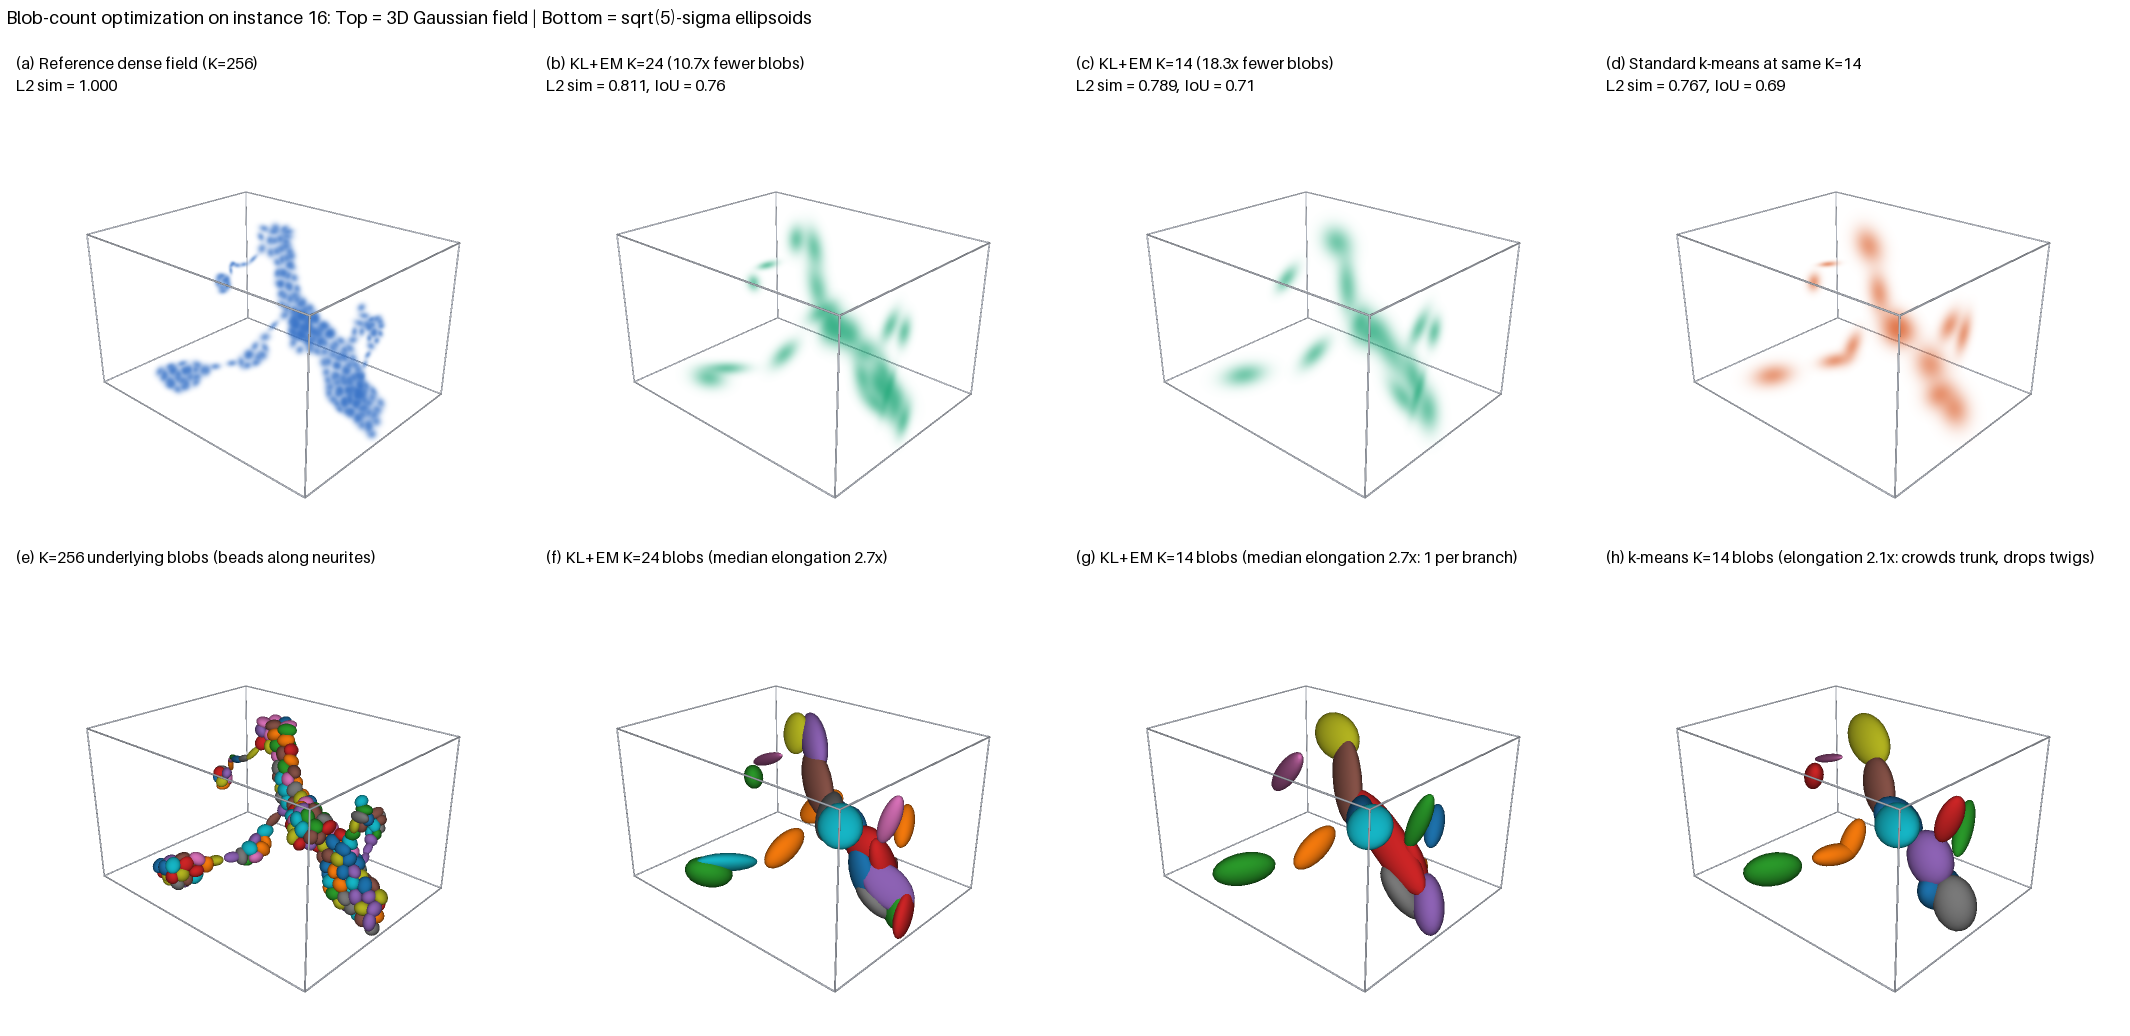

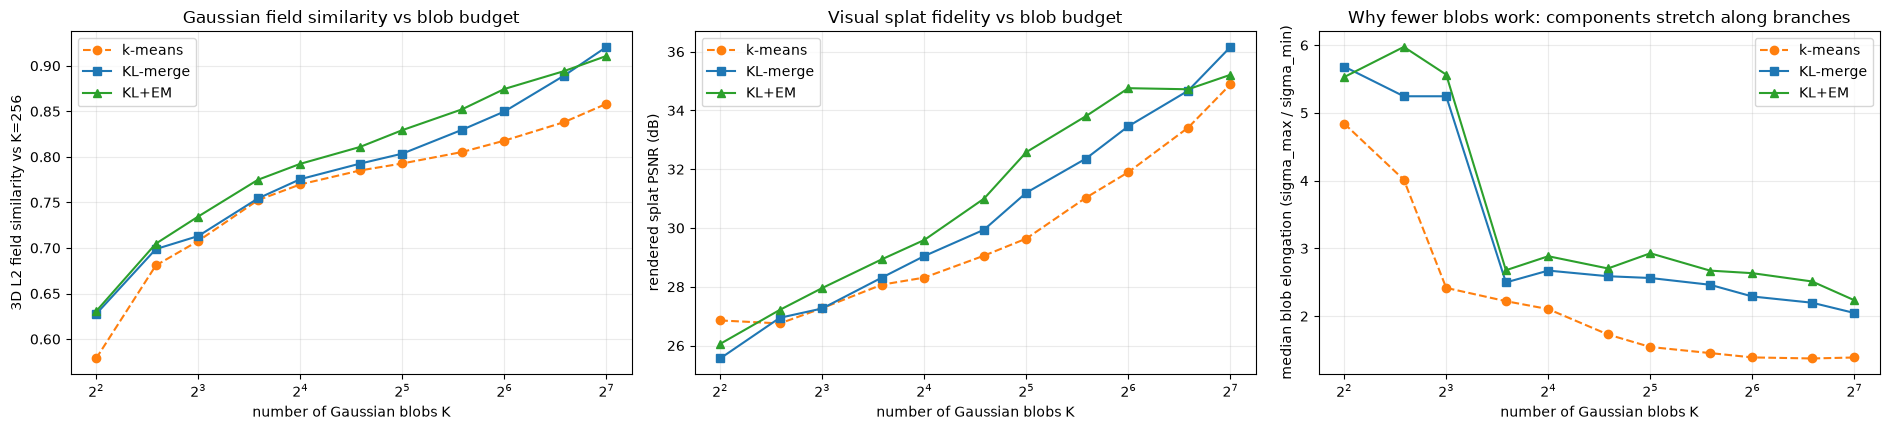

In [16]:
# Visual proof on instance i_demo: continuous 3D Gaussian field (top) and underlying ellipsoid blobs (bottom),
# comparing Reference K=256 vs Optimized KL+EM at K=24 and K=14 vs standard k-means at K=14.
g_em24 = em_anisotropic_gmm(pts_demo_fit, grid_demo.voxel_size_xyz_nm, snaps256[24], n_iter=18)
g_em14 = em_anisotropic_gmm(pts_demo_fit, grid_demo.voxel_size_xyz_nm, snaps256[14], n_iter=18)
g_km14 = C.instance_to_gaussians(sub_demo, grid_demo, k=14, seed=0)


def render_field_and_blobs(g, col):
    s_f = emray.Scene(); s_f.add_wire_box(lo_d, hi_d, color=(0.76, 0.78, 0.82), min_pixels=1.0)
    s_f.add_gaussian_mixture(g, grid_demo, opacity=0.62, color=col)
    s_b = emray.Scene(); s_b.add_wire_box(lo_d, hi_d, color=(0.76, 0.78, 0.82), min_pixels=1.0)
    s_b.add_gaussian_mixture(g, grid_demo, sigma_surface=np.sqrt(TAU))
    return s_f.render(cam_d), s_b.render(cam_d, hemisphere=0.35)


p_ref = render_field_and_blobs(g_ref256, (0.22, 0.45, 0.78))
p_e24 = render_field_and_blobs(g_em24, (0.14, 0.66, 0.48))
p_e14 = render_field_and_blobs(g_em14, (0.14, 0.66, 0.48))
p_k14 = render_field_and_blobs(g_km14, (0.86, 0.38, 0.18))

opt_pic = figure.montage(
    [p_ref[0], p_e24[0], p_e14[0], p_k14[0], p_ref[1], p_e24[1], p_e14[1], p_k14[1]],
    captions=[
        f"Reference dense field (K=256)\nL2 sim = 1.000",
        f"KL+EM K=24 (10.7x fewer blobs)\nL2 sim = {gaussian_l2_similarity(g_em24, g_ref256, n_ref256):.3f}, IoU = {overlap(draw_gaussians(g_em24, grid_demo), sub_demo)['iou']:.2f}",
        f"KL+EM K=14 (18.3x fewer blobs)\nL2 sim = {gaussian_l2_similarity(g_em14, g_ref256, n_ref256):.3f}, IoU = {overlap(draw_gaussians(g_em14, grid_demo), sub_demo)['iou']:.2f}",
        f"Standard k-means at same K=14\nL2 sim = {gaussian_l2_similarity(g_km14, g_ref256, n_ref256):.3f}, IoU = {overlap(draw_gaussians(g_km14, grid_demo), sub_demo)['iou']:.2f}",
        "K=256 underlying blobs (beads along neurites)",
        f"KL+EM K=24 blobs (median elongation {np.median(g_em24.elongation()):.1f}x)",
        f"KL+EM K=14 blobs (median elongation {np.median(g_em14.elongation()):.1f}x: 1 per branch)",
        f"k-means K=14 blobs (elongation {np.median(g_km14.elongation()):.1f}x: crowds trunk, drops twigs)",
    ],
    ncols=4, pad=10, labels=True,
)
figure.show(figure.caption(opt_pic, f"Blob-count optimization on instance {i_demo}: Top = 3D Gaussian field   |   Bottom = sqrt(5)-sigma ellipsoids", size=18))

fig, axs = plt.subplots(1, 3, figsize=(19, 4.4))
for m_name, mk, col in (("k-means", "o--", "tab:orange"), ("KL-merge", "s-", "tab:blue"), ("KL+EM", "^-", "tab:green")):
    sub_df = SWEEP[SWEEP.method == m_name]
    axs[0].plot(sub_df.K, sub_df.l2_sim, mk, color=col, label=m_name)
    axs[1].plot(sub_df.K, sub_df.psnr_db, mk, color=col, label=m_name)
    axs[2].plot(sub_df.K, sub_df.elong, mk, color=col, label=m_name)
axs[0].set_xscale("log", base=2); axs[0].set_xlabel("number of Gaussian blobs K"); axs[0].set_ylabel("3D L2 field similarity vs K=256")
axs[0].set_title("Gaussian field similarity vs blob budget"); axs[0].legend(); axs[0].grid(alpha=0.25)
axs[1].set_xscale("log", base=2); axs[1].set_xlabel("number of Gaussian blobs K"); axs[1].set_ylabel("rendered splat PSNR (dB)")
axs[1].set_title("Visual splat fidelity vs blob budget"); axs[1].legend(); axs[1].grid(alpha=0.25)
ks_cost = sorted(snaps256["_step_costs"])
axs[2].set_xscale("log", base=2); axs[2].set_xlabel("number of Gaussian blobs K"); axs[2].set_ylabel("median blob elongation (sigma_max / sigma_min)")
axs[2].set_title("Why fewer blobs work: components stretch along branches"); axs[2].legend(); axs[2].grid(alpha=0.25)
fig.tight_layout(); plt.show()

optimized minimum blob count K* (target L2 similarity >= 0.85) across 400 instances in 45.4 s

                         total blobs (all neurons)  median K* IQR (25-75%)  compression vs M=128  compression vs k-means
Dense reference (M=128)                      51200      128.0      128-128                  1.00                    0.40
Standard k-means K*                          20272       50.0        46-55                  2.53                    1.00
KL-moment merge K*                           11194       28.0        26-30                  4.57                    1.81
KL+EM optimized K*                            6859       17.0        14-20                  7.46                    2.96

What drives K*? Spearman correlation of KL+EM K* with skeleton cable length = 0.68, with branch points = 0.34; median blob elongation rises to 2.81x.


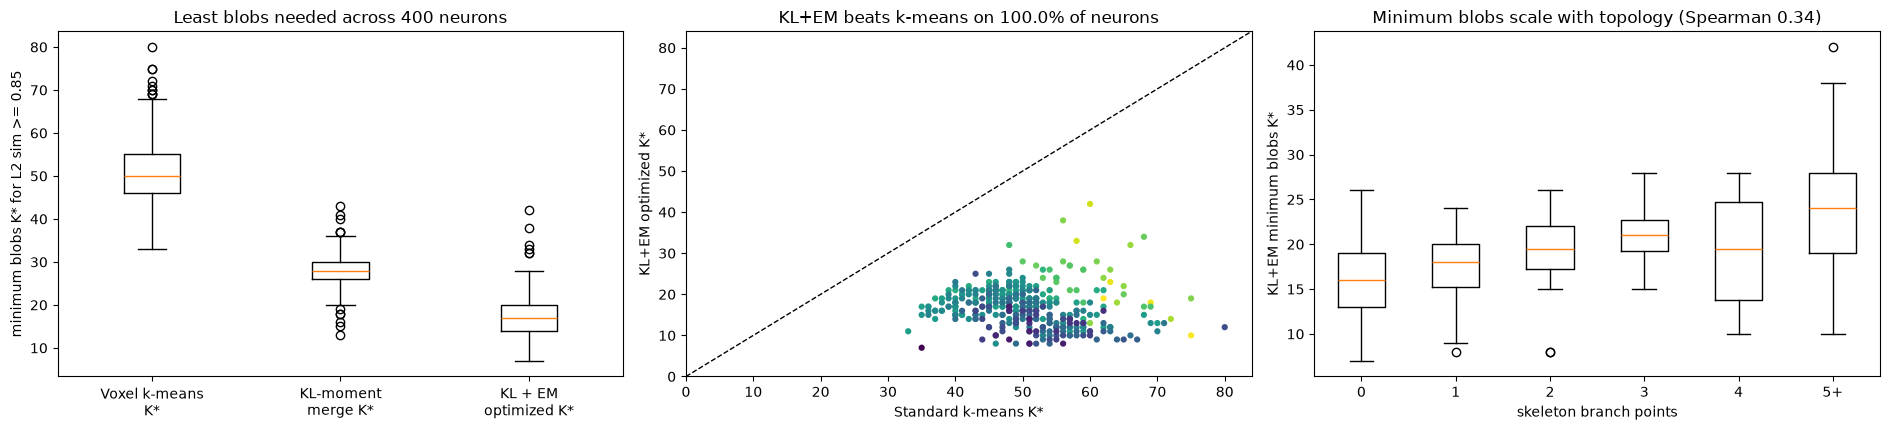

In [17]:
# Dataset-wide optimization across all 400 neurons in AC4_labels.h5:
# find the MINIMUM K* per neuron such that L2 field similarity against its dense M=128 Gaussian field is >= SIM_TARGET.
def _opt_instance(idx):
    idx = int(idx)
    rng_ = np.random.default_rng(idx)
    sub_, grid_, _ = crop_instance(idx)
    k_ref = min(M_REF, int(sub_.sum()))
    g_ref_ = C.instance_to_gaussians(sub_, grid_, k=k_ref, seed=0, max_points=25_000)
    n_ref_ = gaussian_l2_inner(g_ref_, g_ref_)
    snaps_ = kl_merge_hierarchy(g_ref_)
    pts_ = grid_.voxel_centers_nm(np.argwhere(sub_))
    pts_fit_ = pts_ if len(pts_) <= 12_000 else pts_[rng_.choice(len(pts_), 12_000, replace=False)]

    # 1. Minimum K* for KL-merge (binary search on precomputed hierarchy)
    lo_k, hi_k = 1, k_ref
    while lo_k < hi_k:
        mid = (lo_k + hi_k) // 2
        if gaussian_l2_similarity(snaps_[mid], g_ref_, n_ref_) >= SIM_TARGET:
            hi_k = mid
        else:
            lo_k = mid + 1
    k_kl = lo_k

    # 2. Minimum K* for KL+EM (binary search in 1..k_kl)
    lo_k, hi_k = 1, k_kl
    best_em = snaps_[k_kl]
    while lo_k < hi_k:
        mid = (lo_k + hi_k) // 2
        ge = em_anisotropic_gmm(pts_fit_, grid_.voxel_size_xyz_nm, snaps_[mid], n_iter=12)
        if gaussian_l2_similarity(ge, g_ref_, n_ref_) >= SIM_TARGET:
            hi_k = mid
            best_em = ge
        else:
            lo_k = mid + 1
    k_em = len(best_em)

    # 3. Minimum K* for standard k-means (binary search in k_em..k_ref)
    lo_k, hi_k = k_em, k_ref
    while lo_k < hi_k:
        mid = (lo_k + hi_k) // 2
        gk = C.instance_to_gaussians(sub_, grid_, k=mid, seed=0, max_points=12_000)
        if gaussian_l2_similarity(gk, g_ref_, n_ref_) >= SIM_TARGET:
            hi_k = mid
        else:
            lo_k = mid + 1
    k_km = lo_k
    return dict(id=idx, k_ref=k_ref, k_km=k_km, k_kl=k_kl, k_em=k_em,
                elong_em=float(np.median(best_em.elongation())))


t0 = time.time()
if WORKERS > 1:
    with mp.get_context("fork").Pool(min(WORKERS, os.cpu_count()), initializer=_one_thread) as pool:
        opt_rows = pool.map(_opt_instance, [int(i) for i in IDS], chunksize=2)
else:
    opt_rows = [_opt_instance(i) for i in IDS]
OPT = pd.DataFrame(opt_rows).set_index("id").loc[IDS].join(R[["n_vox", "cable_um", "n_branch", "skel_edges"]])
print(f"optimized minimum blob count K* (target L2 similarity >= {SIM_TARGET}) across {len(OPT)} instances in {time.time() - t0:.1f} s\n")

opt_summary = pd.DataFrame({
    "Dense reference (M=128)": OPT.k_ref,
    "Standard k-means K*": OPT.k_km,
    "KL-moment merge K*": OPT.k_kl,
    "KL+EM optimized K*": OPT.k_em,
})
print(pd.DataFrame({
    "total blobs (all neurons)": opt_summary.sum(),
    "median K*": opt_summary.median(),
    "IQR (25-75%)": [f"{opt_summary[c].quantile(.25):.0f}-{opt_summary[c].quantile(.75):.0f}" for c in opt_summary],
    "compression vs M=128": (opt_summary["Dense reference (M=128)"].sum() / opt_summary.sum()).round(2),
    "compression vs k-means": (opt_summary["Standard k-means K*"].sum() / opt_summary.sum()).round(2),
}).to_string())

rho_br, _ = stats.spearmanr(OPT.n_branch, OPT.k_em)
rho_cb, _ = stats.spearmanr(OPT.cable_um, OPT.k_em)
print(f"\nWhat drives K*? Spearman correlation of KL+EM K* with skeleton cable length = {rho_cb:.2f}, "
      f"with branch points = {rho_br:.2f}; median blob elongation rises to {OPT.elong_em.median():.2f}x.")

fig, axs = plt.subplots(1, 3, figsize=(19, 4.4))
axs[0].boxplot([OPT.k_km, OPT.k_kl, OPT.k_em], tick_labels=["Voxel k-means\nK*", "KL-moment\nmerge K*", "KL + EM\noptimized K*"])
axs[0].set_ylabel(f"minimum blobs K* for L2 sim >= {SIM_TARGET}"); axs[0].set_title("Least blobs needed across 400 neurons")
axs[1].scatter(OPT.k_km, OPT.k_em, s=12, c=np.log10(OPT.n_vox), cmap="viridis")
mx_k = int(OPT.k_km.max()) + 4
axs[1].plot([0, mx_k], [0, mx_k], "k--", lw=1); axs[1].set_xlim(0, mx_k); axs[1].set_ylim(0, mx_k)
axs[1].set_xlabel("Standard k-means K*"); axs[1].set_ylabel("KL+EM optimized K*")
axs[1].set_title(f"KL+EM beats k-means on {(OPT.k_em < OPT.k_km).mean():.1%} of neurons")
grp_b = OPT.n_branch.clip(upper=5).astype(int)
lv_b = sorted(grp_b.unique())
axs[2].boxplot([OPT.k_em[grp_b == g_] for g_ in lv_b], tick_labels=[str(g_) if g_ < 5 else "5+" for g_ in lv_b])
axs[2].set_xlabel("skeleton branch points"); axs[2].set_ylabel("KL+EM minimum blobs K*")
axs[2].set_title(f"Minimum blobs scale with topology (Spearman {rho_br:.2f})")
fig.tight_layout(); plt.show()

## 11. Findings

Printed from the numbers above, so they follow the data when `LABELS`, the parameters or the converters change.

In [18]:
f = []
f.append(f"{len(R)} instances in {LABELS}: the 10 largest hold {COUNTS[IDS[:10]].sum() / COUNTS[IDS].sum():.0%} of the labelled voxels; "
         f"{(INV.n_comp > 1).mean():.0%} are split into several pieces inside this crop and {(INV.n_faces_touched > 0).mean():.0%} are cut by the array border, "
         f"so every representation describes a fragment of a neuron, not the whole cell.")
f.append(f"skeleton: median mean radius {S.radius_nm.median():.0f} nm ({S.radius_nm.median() / min(vx, vy):.0f} in-plane voxels, {S.radius_nm.median() / vz:.1f} sections); "
         f"cable ~ volume^{sl:.2f}; V/(pi r^2 L) = {big.cylinder_ratio.median():.2f} (neurites have non-round cross-sections, swellings and spines beyond the inscribed tube); "
         f"balls of the node radius cover {S.skel_ball_recall.median():.0%} of the voxels at {S.skel_ball_precision.median():.0%} precision. "
         f"The raw chain of voxel centres is {100 * (S.tortuosity_gain.median() - 1):.0f}% longer than its smoothed version.")
f.append(f"wiremesh: loses {100 * (1 - M.vol_ratio.median()):.2f}% volume to corner cutting (median), has {M.roughness.median():.1f}x the area of an equal-volume sphere, "
         f"{M.faces_per_vox.median():.2f} faces per voxel; simplify_factor=10 keeps {(ok.mesh10_faces / ok.mesh_faces).median():.0%} of the faces and changes the volume by {ok.simp_vol_err.median():+.2f}%.")
f.append(f"gaussian (voxel k-means): median IoU {R.gauss1_iou.median():.2f} / {R.gauss4_iou.median():.2f} / {R.gauss16_iou.median():.2f} / {R.gauss64_iou.median():.2f} for K = 1 / 4 / 16 / 64; "
         f"skeleton -> gaussian at K ~ {SKEL_K_LIST[1]} reaches IoU {R[f'sg{SKEL_K_LIST[1]}_iou'].median():.2f} ({R[f'sgx{SKEL_K_LIST[1]}_iou'].median():.2f} with radius x {INFLATE}) vs {R[f'vg{SKEL_K_LIST[1]}_iou'].median():.2f} on voxels.")
f.append(f"progression voxel -> frame -> graph (instance {i_demo}): primitive count drops {counts_full['bricks']:,} shell bricks -> "
         f"{counts_full['faces']:,} surface-frame triangles -> {counts_full['edges']:,} graph edges, and every stage renders natively as both a discrete wiremesh and a 3D Gaussian field.")
f.append(f"blob-count optimization (least Gaussians for L2 field similarity >= {SIM_TARGET} against M={M_REF} across all {len(OPT)} neurons): "
         f"standard k-means needs median K* = {OPT.k_km.median():.0f} ({OPT.k_km.sum():,} total blobs), greedy KL-moment merging cuts this to "
         f"K* = {OPT.k_kl.median():.0f} ({OPT.k_kl.sum():,}), and KL+anisotropic EM reaches K* = {OPT.k_em.median():.0f} ({OPT.k_em.sum():,} total, "
         f"{OPT.k_ref.sum() / OPT.k_em.sum():.1f}x fewer than dense and {OPT.k_km.sum() / OPT.k_em.sum():.1f}x fewer than k-means) by stretching ellipsoids "
         f"to median elongation {OPT.elong_em.median():.1f}x along straight neurite branches.")
f.append(f"anisotropy & cost: treating 6x6x30 nm voxels as cubes changes cable length by {aniso['cable_length_nm']:+.0f}% and drops K=16 Gaussian IoU from "
         f"{res['correct']['iou']:.2f} to {res['same_clusters_scaled']['iou']:.2f} when covariance scaling is omitted. "
         f"At K* = {OPT.k_em.median():.0f} ({40 * int(OPT.k_em.median())} B per neuron), the optimized Gaussian mixture is ~{int(summary.loc['mask bbox (1 bit/voxel)', 'median bytes'] / (40 * OPT.k_em.median())):,}x smaller than the 1-bit bbox mask.")
for line in f:
    print("-", line, "\n")

- 400 instances in AC4_labels.h5: the 10 largest hold 32% of the labelled voxels; 1% are split into several pieces inside this crop and 100% are cut by the array border, so every representation describes a fragment of a neuron, not the whole cell. 

- skeleton: median mean radius 75 nm (12 in-plane voxels, 2.5 sections); cable ~ volume^0.68; V/(pi r^2 L) = 1.56 (neurites have non-round cross-sections, swellings and spines beyond the inscribed tube); balls of the node radius cover 62% of the voxels at 100% precision. The raw chain of voxel centres is 25% longer than its smoothed version. 

- wiremesh: loses 0.25% volume to corner cutting (median), has 2.5x the area of an equal-volume sphere, 0.94 faces per voxel; simplify_factor=10 keeps 10% of the faces and changes the volume by -0.17%. 

- gaussian (voxel k-means): median IoU 0.34 / 0.67 / 0.77 / 0.82 for K = 1 / 4 / 16 / 64; skeleton -> gaussian at K ~ 16 reaches IoU 0.51 (0.68 with radius x 1.25) vs 0.77 on voxels. 

- progression v